# The cell problem as a pair of convex programs: certified brackets, Keller-Dykhne on the grid, and corner-limited convergence

The effective tensor $\sigma^*$ of a periodic two-phase medium is the value of a convex minimization, the Dirichlet principle for the potential, and its inverse is the value of a second one, the Thomson principle for the flux. A conforming discretization of either one lands on a known side of the truth. A pair of them is therefore a certificate: an interval, in the Loewner order, that contains $\sigma^*$ whatever the mesh. This notebook asks what the two discretizations certify, which duality identities they satisfy exactly on the grid, and what limits the speed at which the certified interval closes. It then asks the same of true geometries (disks, with exact coefficients) and of finite windows of a random medium.

It matters because every later notebook in this folder measures effective tensors with these solvers. Here their numerical error is turned into a rigorous interval, the discrete pair is shown to respect the Keller-Dykhne interchange exactly, and the slow convergence of pixel solvers at high contrast is traced to the exponent of the four-tile corner, so that the reader gets certificates in place of convergence plots.

## What this notebook shows

- The Q1 primal value $U_h$ and the dual value $L_h=(R^{\mathsf T}U_h[1/\sigma]R)^{-1}$ bracket the effective tensor of any pixel field in the Loewner order, are exact on grid-aligned laminates, and are monotone under $2\times2$ pixel refinement (section 1). On ten random fields the smallest eigenvalue of $U_h-L_h$ is $0.68$, so these brackets are wide.
- On the checkerboard, the discrete Keller identity $L_hU_h=ab$ holds to rounding at every size and contrast tried (at most $1.4\times10^{-12}$ over eighteen cases, $N=16,\dots,512$, $\kappa=4,10,100$), because the swapped checkerboard is a translate and a rotation of itself on an even grid. The product of two primal values is not exact: at $\kappa=10$, $N=64$ it misses by $0.059$, which equals $2e_N+e_N^2$ for the relative primal error $e_N$ (section 2). A second identity of the same kind, $L_hU_h=(1+3h)/(3+h)$ on the quarter-square array, is observed (not derived) to hold to $1.2\times10^{-13}$ in nine cases (section 2).
- The exponents of the four-tile corner are the two roots of an $8\times8$ matching system. Numerical roots and the closed form $\lambda_1=\tfrac4\pi\arctan\kappa^{-1/2}$, $2-\lambda_1$ agree to $10^{-15}$. The Q1 local rate approaches $2\lambda_1$ from above: for $\kappa=4$ and $10$ the last local rates are $1.1809$ and $0.7829$ against $1.1807$ and $0.7799$. For $\kappa=10$ the power-law fit of the rates has $r_\infty=0.7805$ and its spreads lie $3\times10^{-4}$ to $10^{-3}$ above $2\lambda_1$, so even there the fit does not contain $2\lambda_1$. For $\kappa=100$ the last rate is still $0.3040$ against $0.2538$ at $N=256\to512$. On the Q1 data alone the power-law fit puts the limit at $0.272$, above $2\lambda_1$ and outside its own spread ($0.267$ to $0.276$); only the corner theory and the pre-asymptotic scale $N^*=e^{1/\lambda_1}\approx2.6\times10^3$ argue for $2\lambda_1$. A logarithmic correction is a numerical device ($0.226$), not a competing hypothesis (section 3).
- The sampled-coefficient (Moulinec-Suquet) scheme is the more accurate one on the checkerboard, by a factor of about $23$ at $\kappa=10$, $N=256$, and its iteration count is nearly independent of $N$, but it has no certificate. Its local rate at $\kappa=10$ stays in $1.27$ to $1.29$ for $N=32$ to $2048$; at $\kappa=100$ it falls from $0.53$ to $0.45$ without settling. None of the candidate laws $2\lambda_1$, $4\lambda_1$, $2\lambda_1+\tfrac12$ describes both contrasts (section 3).
- For true disks, the Fourier-Galerkin pair with exact coefficients is a rigorous bracket of the Rayleigh multipole value, closes like $1/K$ (slopes $-1.00$, $-1.04$, $-1.00$ in three cases), and is lopsided: for these disks stronger than the host the upper bound's distance to the truth is $1.02$ to $1.07$ times $\kappa$ times the lower bound's, so the midpoint is biased by $3.7\times10^{-3}$ at $K=64$ for $(f,\kappa)=(0.5,10)$. Linear extrapolation in $1/K$ recovers the Rayleigh value to $9\times10^{-6}$ at $(0.5,10)$ (not rigorous); at $(0.5,100)$ the extrapolated upper bound is $2.9\times10^{-4}$ below it (section 4).
- Staircase disks are not true disks of the same area: in eight of nine tested cases the certified pixel bracket excludes the Rayleigh value at the pixel area fraction. For the $f=0.5$ geometry both endpoints of the certified shape-part interval shrink by $2.1$ to $2.5$ per doubling of $N$, and a finer solver mesh on the fixed $N=64$ and $128$ staircases certifies a decrease of the shape part by a factor of at least $1.9$; this is consistent with an $O(h)$ perimeter effect but is not a certified rate. At $f=0.7$ the certified shape part is not monotone in $N$, and the shape/area ratio at one $N$ depends on an area part that changes sign (section 4).
- For windows of a random checkerboard, the four apparent tensors are ordered in every one of $96$ realizations. The antithetic identity $\det U_{\rm per}[\sigma]\det L_{\rm per}[\sigma']=(ab)^2$ holds to rounding but is the interchange identity again (a unit test). The scatter of $(U_{\rm per})_{xx}$ falls with a fitted slope $-1.14\pm0.21$ in $L$, which is not inconsistent with $-1$ but has low power to discriminate. The relative half-width of the ensemble bracket is set by the pixels per tile: $1.075$, $1.039$, $1.022$ at $m=2,4,8$ for $L=8$ (section 5).

## Conventions

Scalar conductivity $\sigma>0$ on the torus $\mathbb T^2=\mathbb R^2/\mathbb Z^2$; lengths are in units of the period. For the static in-plane problem of electrodynamics, the permittivity plays the role of $\sigma$ (the TE static limit; the time dependence $e^{-i\omega t}$ is irrelevant at zero frequency). Two phases $a<b$ with contrast $\kappa=b/a$, and $a=1$ except where a case says otherwise. Pixel fields are $N\times N$ arrays $\sigma[i,j]$ with $i$ the $x$ index, pixel centers at $((i+\tfrac12)/N,(j+\tfrac12)/N)$ and Q1 nodes at the pixel corners. $R=\begin{pmatrix}0&-1\\1&0\end{pmatrix}$ is the rotation by $90^\circ$. $U_h[\sigma]$ is the Q1 (primal) value, a symmetric $2\times2$ matrix; $L_h[\sigma]$ the dual value; $\sigma'=ab/\sigma$ is the phase-swapped field (equal to $\min+\max-\sigma$ for two values). Every check prints PASS or FAIL and asserts. A tolerance is marked "a priori" when it comes from rounding or from a theorem, and "set after seeing" when a convergence study or the printed results fixed it; the second kind is listed in the caveats.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported
os.environ.setdefault("NPROC", "4")  # size of the XLA CPU thread pool (never 2: see scripts/batch_run.py)
os.environ.setdefault("XLA_FLAGS", "--xla_cpu_multi_thread_eigen=" + ("false" if os.environ["NPROC"] == "1" else "true"))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/homogenization (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name


def check_in(name, value, lo, hi):
    """Print PASS or FAIL for lo <= value <= hi (a bound, an interval, a sign) and assert it."""
    ok = lo <= value <= hi
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, required in [{lo:.6g}, {hi:.6g}]")
    assert ok, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # the modules sit next to this notebook
import cellsolver as cs
import bounds as bd
import rayleigh as ry
from scipy.optimize import minimize_scalar

T0 = time.perf_counter()
SEC = {}                                              # seconds spent per section, printed at the end
R90 = np.array([[0.0, -1.0], [1.0, 0.0]])            # the rotation R of the text
A_, B_ = 1.0, 10.0                                    # the two phase values of section 1
print("modules loaded; thread caps:", {k: os.environ[k] for k in ("OMP_NUM_THREADS", "NPROC")})

modules loaded; thread caps: {'OMP_NUM_THREADS': '4', 'NPROC': '4'}


## 1. Two minimum principles, one solver

Let $\sigma$ be bounded, measurable and uniformly positive on $\mathbb T^2$. For $e\in\mathbb R^2$ the corrector $\chi_e\in H^1_{\rm per}$ solves $-\nabla\cdot\sigma(e+\nabla\chi_e)=0$, and $\sigma^*e=\langle\sigma(e+\nabla\chi_e)\rangle$. Two variational characterizations hold:

$$e\cdot\sigma^*e=\min_{\varphi\in H^1_{\rm per}}\big\langle\sigma\,|e+\nabla\varphi|^2\big\rangle,\qquad e\cdot(\sigma^*)^{-1}e=\min\Big\{\big\langle\sigma^{-1}|J|^2\big\rangle:\;J\in L^2_{\rm per},\ \nabla\!\cdot\! J=0,\ \langle J\rangle=e\Big\}.$$

In two dimensions the divergence-free periodic fields with mean $e$ are $J=e+R\nabla\psi$ with $\psi\in H^1_{\rm per}$ (Hodge decomposition on the torus), and $|J|^2=|R^{\mathsf T}e+\nabla\psi|^2$. So the flux principle is the potential principle for $1/\sigma$, evaluated at the rotated direction $R^{\mathsf T}e$:

$$(\sigma^*[\sigma])^{-1}=R\,\sigma^*[1/\sigma]\,R^{\mathsf T}\qquad(\text{for symmetric }2\times2\text{ matrices }R\,M\,R^{\mathsf T}=R^{\mathsf T}MR).$$

This is the Keller-Mendelson interchange relation in tensor form, valid for every coefficient field in two dimensions. Let $U_h[\tau]$ be the minimum of the primal energy of $\tau$ over the periodic Q1 space on an $N\times N$ pixel mesh. For a pixel field this is the exact minimum of the exact energy over a conforming subspace, with no quadrature error and with the pixel size $h$ canceling from the element matrix, which for nodes $(i,j),(i{+}1,j),(i{+}1,j{+}1),(i,j{+}1)$ is $\sigma_eK_0$ with

$$K_0=\frac16\begin{pmatrix}4&-1&-2&-1\\-1&4&-1&-2\\-2&-1&4&-1\\-1&-2&-1&4\end{pmatrix},$$

and with load integrals $\int\partial_xN=h(-\tfrac12,\tfrac12,\tfrac12,-\tfrac12)$ and $\int\partial_yN=h(-\tfrac12,-\tfrac12,\tfrac12,\tfrac12)$. Define

$$L_h[\sigma]:=\big(R^{\mathsf T}\,U_h[1/\sigma]\,R\big)^{-1}.$$

**Claim.** For every pixel field, $U_h[\sigma]\ \ge\ \sigma^*[\sigma]\ \ge\ L_h[\sigma]$ in the Loewner order. *Proof.* The first inequality is the minimum over a subspace. For the second, $U_h[1/\sigma]\ge\sigma^*[1/\sigma]$ by the first; conjugation by $R$ preserves the order and inversion reverses it, so $L_h=(R^{\mathsf T}U_h[1/\sigma]R)^{-1}\le(R^{\mathsf T}\sigma^*[1/\sigma]R)^{-1}=\sigma^*[\sigma]$. $\square$ Both values are monotone under $2\times2$ pixel replication of a fixed medium, because a bilinear function on a coarse pixel is bilinear on its four sub-pixels: the Q1 spaces are nested, $U_h$ decreases and $L_h$ increases. The bracket is a statement about the *pixel medium*; whether it brackets a smooth geometry is a different question (section 4).

*Computations.* (a) Laminates, $N=64$, a centered stripe of 32 pixels of phase $b=10$ in phase $a=1$, layer normal along $x$ and along $y$. The exact corrector is piecewise linear with kinks on grid lines, so it lies in the Q1 space of the primal problem and, for $1/\sigma$, of the dual one: both bounds should equal the Wiener means. (b) Ten random two-phase pixel fields, $N=32$, $p=\tfrac12$, seeds $0$ to $9$: Loewner order, and the discrete interchange identity $U_h[\sigma']=ab\,R\,L_h[\sigma]^{-1}R^{\mathsf T}$, which is the definition of $L_h$ rewritten and so a unit test of the rotation convention. (c) The checkerboard $(a,b)=(1,10)$ at $N=16,32,64$, each obtained from the previous one by $2\times2$ replication.

In [3]:
t_sec = time.perf_counter()

# (a) laminates: N = 64, a centered stripe of 32 pixels of phase B in phase A; axis = layer normal
harm, arith = bd.wiener(A_, B_, 0.5)
print(f"Wiener means for 50/50 of {A_:g} and {B_:g}: harmonic {harm:.6f} (across the layers), arithmetic {arith:.6f} (along them)")
print(f"{'layer normal':>13s} {'L_xx':>10s} {'U_xx':>10s} {'L_yy':>10s} {'U_yy':>10s}   exact (xx, yy)")
lam_err = 0.0
for axis, name in ((0, "x"), (1, "y")):
    L_, U_ = cs.q1_bracket(cs.laminate_pixels(64, 32, B_, A_, axis))
    exact = np.diag([harm, arith] if axis == 0 else [arith, harm])
    lam_err = max(lam_err, np.abs(L_ - exact).max(), np.abs(U_ - exact).max())
    print(f"{name:>13s} {L_[0, 0]:10.6f} {U_[0, 0]:10.6f} {L_[1, 1]:10.6f} {U_[1, 1]:10.6f}   ({exact[0, 0]:.6f}, {exact[1, 1]:.6f})")
check("laminates, both orientations: every entry of L_h and U_h against the Wiener mean", lam_err, 1e-12)

# (b) ten random two-phase pixel fields, N = 32, p = 1/2, and their phase-swapped fields
def random_pixels(seed, N=32):
    return np.where(np.random.default_rng(seed).random((N, N)) < 0.5, B_, A_)

rows, min_eig, inter_err = [], [], []
for seed in range(10):
    s = random_pixels(seed)
    L_, U_ = cs.q1_bracket(s)
    U_sw = cs.q1_effective(cs.swap_phases(s))
    min_eig.append(np.linalg.eigvalsh(U_ - L_).min())
    inter_err.append(np.linalg.norm(U_sw - A_ * B_ * R90 @ np.linalg.inv(L_) @ R90.T) / np.linalg.norm(U_sw))
    rows.append((seed, L_[0, 0], U_[0, 0], L_[1, 1], U_[1, 1], min_eig[-1], inter_err[-1]))
print("\nten random fields, N = 32:")
print(f"{'seed':>4s} {'L_xx':>8s} {'U_xx':>8s} {'L_yy':>8s} {'U_yy':>8s} {'min eig(U-L)':>13s} {'interchange rel. error':>23s}")
for r_ in rows:
    print(f"{r_[0]:4d} {r_[1]:8.4f} {r_[2]:8.4f} {r_[3]:8.4f} {r_[4]:8.4f} {r_[5]:13.4e} {r_[6]:23.2e}")
check_in("Loewner order: smallest eigenvalue of U_h - L_h over the 10 fields", min(min_eig), -1e-12, np.inf)
check("discrete interchange identity U_h[ab/sigma] = ab R inv(L_h[sigma]) R^T, worst of 10", max(inter_err), 1e-10)

# (c) the checkerboard by 2x2 pixel replication: nested spaces
chk = {16: cs.checkerboard(16, A_, B_)}
for N in (32, 64):
    chk[N] = np.kron(chk[N // 2], np.ones((2, 2)))
    assert np.array_equal(chk[N], cs.checkerboard(N, A_, B_))       # replication is the generator's own checkerboard
br = {N: cs.q1_bracket(chk[N]) for N in chk}
print("\ncheckerboard (1, 10) refined by 2x2 pixel replication:")
for N in chk:
    print(f"  N = {N:3d}:  L_xx = {br[N][0][0, 0]:.6f}   U_xx = {br[N][1][0, 0]:.6f}")
slack = min(br[16][1][0, 0] - br[32][1][0, 0], br[32][1][0, 0] - br[64][1][0, 0],
            br[32][0][0, 0] - br[16][0][0, 0], br[64][0][0, 0] - br[32][0][0, 0])
check_in("monotone under refinement: smallest of U(16)-U(32), U(32)-U(64), L(32)-L(16), L(64)-L(32)", slack, -1e-12, np.inf)
SEC["1"] = time.perf_counter() - t_sec

Wiener means for 50/50 of 1 and 10: harmonic 1.818182 (across the layers), arithmetic 5.500000 (along them)
 layer normal       L_xx       U_xx       L_yy       U_yy   exact (xx, yy)
            x   1.818182   1.818182   5.500000   5.500000   (1.818182, 5.500000)
            y   5.500000   5.500000   1.818182   1.818182   (5.500000, 1.818182)
PASS  laminates, both orientations: every entry of L_h and U_h against the Wiener mean: got 2.66454e-14, target 0, |diff| 2.66e-14 <= 1e-12

ten random fields, N = 32:
seed     L_xx     U_xx     L_yy     U_yy  min eig(U-L)  interchange rel. error
   0   2.5511   3.4332   2.5489   3.4368    8.5296e-01                1.14e-16
   1   2.7881   3.7010   2.7332   3.5878    8.3115e-01                4.73e-16
   2   2.7046   3.6215   2.6942   3.6484    8.7853e-01                6.62e-16
   3   2.7611   3.6368   2.7644   3.6570    8.6010e-01                2.82e-16
   4   2.5566   3.5126   2.4569   3.2893    8.2494e-01                1.86e-16
   5   2.9771


checkerboard (1, 10) refined by 2x2 pixel replication:
  N =  16:  L_xx = 2.903463   U_xx = 3.444163
  N =  32:  L_xx = 3.009160   U_xx = 3.323187
  N =  64:  L_xx = 3.072227   U_xx = 3.254968
PASS  monotone under refinement: smallest of U(16)-U(32), U(32)-U(64), L(32)-L(16), L(64)-L(32): got 0.0630668, required in [-1e-12, inf]


Both bounds reproduce the Wiener means to rounding on laminates. The Loewner order holds on every random field with a large margin, presumably because independent pixels create many four-pixel corners (a guess; not tested here). The interchange identity is exact to rounding: it is an algebraic identity of the definition (it holds for every two-valued field and every $N$), so passing it says the code applies $R$ and the inverse consistently, nothing about the geometry. The only statement here that depends on the grid is the monotonicity under replication.

## 2. Keller-Dykhne on the grid

The continuum results are Keller's interchange (1964, for lattices of identical cylinders) and its general two-dimensional form (Mendelson 1975), $\sigma^*[ab/\sigma]=ab\,R^{\mathsf T}(\sigma^*[\sigma])^{-1}R$ for two-phase fields, and Dykhne's value $\sqrt{ab}$ for the checkerboard and, in the determinant form $\det\sigma^*=ab$ (the tensor $\sigma^*$ itself equals $\sqrt{ab}\,I$ only for a macroscopically isotropic infinite sample), for random two-phase media of equal fractions whose law is invariant under the swap. The discrete statement is sharper than a convergence result. Write $\sigma'=ab/\sigma$ for the checkerboard $\sigma$ on an even grid, $N=2M$. Then

1. $\sigma'$ is $\sigma$ translated by $M$ pixels, a symmetry of the periodic Q1 mesh, so $U_h[\sigma']=U_h[\sigma]$;
2. $\sigma'$ is also $\sigma$ rotated by $90^\circ$ about the node $(M,M)$, again a mesh symmetry, so $U_h[\sigma']=R\,U_h[\sigma]\,R^{\mathsf T}$.

From 2, $U_h[\sigma]$ commutes with $R$ and is symmetric, hence isotropic, $U_h=u\,I$. The interchange identity of section 1 with $U_h[\sigma']=uI$ gives $L_h=ab/u$. Therefore

$$L_h[\sigma]\,U_h[\sigma]=ab\qquad\text{exactly, at every even }N,$$

the bracket $[ab/u,\,u]$ is symmetric in log scale about $\sqrt{ab}$, and its geometric mean is exact. This answers the question whether the interchange theorem survives discretization: it holds *exactly for the primal-dual pair* on this geometry. For the primal-primal product, $U_h[\sigma]_{xx}U_h[\sigma']_{yy}=u^2=ab(1+e_N)^2$ with $e_N=u/\sqrt{ab}-1$ the relative primal error, which is $2e_N$ to first order and decays only as fast as the discretization converges.

*Computations.* The checkerboard with $a=1$, $b=\kappa\in\{4,10,100\}$ for $N=16,\dots,512$; the pairs $(L_h,U_h)$ are stored for section 3. The primal-primal product at $\kappa=10$ for $N=16,\dots,128$.

In [4]:
t_sec = time.perf_counter()
KAPPAS = (4.0, 10.0, 100.0)
NS = (16, 32, 64, 128, 256, 512)
Q = {}                                  # Q[(kappa, N)] = (L_h, U_h) for the checkerboard (1, kappa)
for kap in KAPPAS:
    for N in NS:
        Q[(kap, N)] = cs.q1_bracket(cs.checkerboard(N, 1.0, kap))

print(f"{'kappa':>5s} {'N':>4s} {'U_xx':>10s} {'L_xx':>10s} {'sqrt(kappa)':>11s} {'|L U/ab - 1|':>13s} {'|U_xy|':>9s} {'|U_xx-U_yy|':>12s}")
dyk, aniso, mono = [], [], []
for kap in KAPPAS:
    for N in NS:
        L_, U_ = Q[(kap, N)]
        dyk.append(abs(L_[0, 0] * U_[0, 0] / kap - 1))
        aniso.append(max(abs(U_[0, 1]), abs(U_[0, 0] - U_[1, 1]), abs(L_[0, 1]), abs(L_[0, 0] - L_[1, 1])))
        print(f"{kap:5g} {N:4d} {U_[0, 0]:10.6f} {L_[0, 0]:10.6f} {np.sqrt(kap):11.6f} {dyk[-1]:13.2e} {abs(U_[0, 1]):9.1e} {abs(U_[0, 0] - U_[1, 1]):12.1e}")
    mono += [Q[(kap, N)][1][0, 0] - Q[(kap, 2 * N)][1][0, 0] for N in NS[:-1]]
    mono += [Q[(kap, 2 * N)][0][0, 0] - Q[(kap, N)][0][0, 0] for N in NS[:-1]]
check("discrete Dykhne identity L_h U_h = ab, all 18 cases (max over kappa, N)", max(dyk), 1e-10)
check("checkerboard tensors are isotropic on the grid (max |U_xy|, |U_xx - U_yy| and the same for L_h)", max(aniso), 1e-10)
check_in("monotone under refinement, all kappa, N = 16 ... 512 (smallest step)", min(mono), -1e-12, np.inf)

# the primal-primal product is not exact
print("\nprimal-primal product U_h[sigma]_xx U_h[sigma_swap]_yy / ab - 1, kappa = 10, against twice the relative primal error:")
pp = {}
for N in (16, 32, 64, 128):
    s = cs.checkerboard(N, 1.0, 10.0)
    Us = cs.q1_effective(cs.swap_phases(s))
    pp[N] = Q[(10.0, N)][1][0, 0] * Us[1, 1] / 10.0 - 1
    e_ = Q[(10.0, N)][1][0, 0] / np.sqrt(10.0) - 1
    print(f"  N = {N:3d}: product - 1 = {pp[N]:.4e}    2 e_N = {2 * e_:.4e}    L_h U_h/ab - 1 = {Q[(10.0, N)][0][0, 0] * Q[(10.0, N)][1][0, 0] / 10 - 1:+.1e}")
ppalg = max(abs(pp[N] - (2 * (Q[(10.0, N)][1][0, 0] / np.sqrt(10.0) - 1) + (Q[(10.0, N)][1][0, 0] / np.sqrt(10.0) - 1) ** 2)) for N in pp)
check("primal-primal product - 1 = 2 e_N + e_N^2 (algebraic consequence of u = sqrt(ab)(1 + e_N)), worst over N = 16 ... 128", ppalg, 1e-12)

# a second exact discrete identity, observed: the square inclusion of side 1/2 (f = 1/4) centered in the cell, host 1, inclusion h
print("\nsquare inclusion of side 1/2 (f = 1/4), host 1, inclusion h: L_h U_h against (1 + 3h)/(3 + h)")
print(f"{'h':>6s} {'N':>4s} {'L_xx':>10s} {'U_xx':>10s} {'sqrt((1+3h)/(3+h))':>19s} {'|L U/((1+3h)/(3+h)) - 1|':>26s}")
sqr = []
for h_ in (0.1, 10.0, 100.0):
    for N in (32, 64, 128):
        s_sq = np.ones((N, N)); s_sq[N // 4:3 * N // 4, N // 4:3 * N // 4] = h_
        L_, U_ = cs.q1_bracket(s_sq)
        sqr.append(abs(L_[0, 0] * U_[0, 0] / ((1 + 3 * h_) / (3 + h_)) - 1))
        print(f"{h_:6g} {N:4d} {L_[0, 0]:10.6f} {U_[0, 0]:10.6f} {np.sqrt((1 + 3 * h_) / (3 + h_)):19.6f} {sqr[-1]:26.2e}")
check("quarter-square array: L_h U_h = (1 + 3h)/(3 + h), worst of 9 cases (observed, not derived)", max(sqr), 1e-10)
SEC["2 (incl. the Q1 table to N = 512)"] = time.perf_counter() - t_sec

kappa    N       U_xx       L_xx sqrt(kappa)  |L U/ab - 1|    |U_xy|  |U_xx-U_yy|
    4   16   2.029599   1.970832    2.000000      0.00e+00   2.3e-17      0.0e+00
    4   32   2.012999   1.987085    2.000000      2.22e-16   1.3e-16      0.0e+00
    4   64   2.005724   1.994292    2.000000      4.44e-16   5.1e-17      4.4e-16
    4  128   2.002523   1.997480    2.000000      2.22e-16   4.7e-16      8.9e-16
    4  256   2.001113   1.998888    2.000000      1.33e-15   2.4e-16      2.7e-15
    4  512   2.000491   1.999509    2.000000      1.55e-15   6.7e-16      3.1e-15
   10   16   3.444163   2.903463    3.162278      2.22e-16   3.0e-16      4.4e-16
   10   32   3.323187   3.009160    3.162278      5.55e-16   7.8e-17      2.7e-15
   10   64   3.254968   3.072227    3.162278      8.88e-16   8.8e-16      1.3e-15
   10  128   3.215927   3.109524    3.162278      6.22e-15   2.1e-15      5.3e-15
   10  256   3.193411   3.131447    3.162278      5.60e-14   8.1e-16      6.2e-15
   10  512   3.1

   0.1  128   0.647464   0.647689            0.647576                   2.66e-15
    10   32   1.542196   1.546247            1.544220                   5.55e-16
    10   64   1.543482   1.544958            1.544220                   3.22e-15


    10  128   1.543952   1.544488            1.544220                   4.00e-15
   100   32   1.705067   1.713909            1.709482                   2.90e-14
   100   64   1.707744   1.711223            1.709482                   2.68e-14


   100  128   1.708799   1.710166            1.709482                   1.23e-13
PASS  quarter-square array: L_h U_h = (1 + 3h)/(3 + h), worst of 9 cases (observed, not derived): got 1.23013e-13, target 0, |diff| 1.23e-13 <= 1e-10


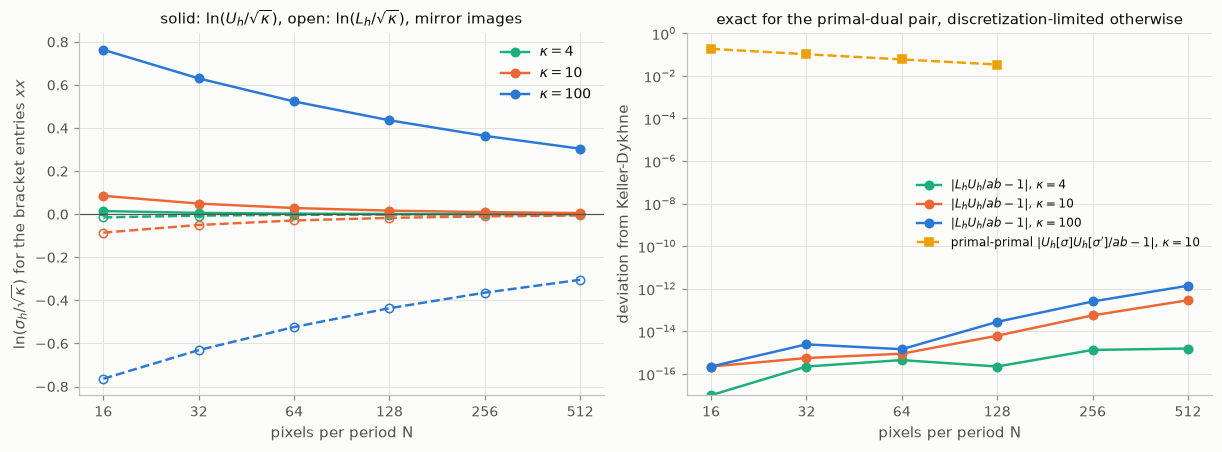

In [5]:
# figure 1: the bracket on the checkerboard, and the two identities
fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
for k, col in zip(KAPPAS, (CAT[2], CAT[1], CAT[0])):
    ax[0].semilogx(NS, [np.log(Q[(k, N)][1][0, 0] / np.sqrt(k)) for N in NS], "o-", color=col, label=rf"$\kappa={k:g}$")
    ax[0].semilogx(NS, [np.log(Q[(k, N)][0][0, 0] / np.sqrt(k)) for N in NS], "o--", mfc="none", color=col)
ax[0].axhline(0, color=INK2, lw=0.8)
ax[0].set_xlabel("pixels per period N"); ax[0].set_ylabel(r"$\ln(\sigma_h/\sqrt{\kappa})$ for the bracket entries $xx$")
ax[0].set_title(r"solid: $\ln(U_h/\sqrt{\kappa})$, open: $\ln(L_h/\sqrt{\kappa})$, mirror images"); ax[0].legend()
ax[0].set_xticks(NS); ax[0].set_xticklabels([str(n) for n in NS]); ax[0].minorticks_off()
for k, col in zip(KAPPAS, (CAT[2], CAT[1], CAT[0])):
    ax[1].semilogy(NS, [max(abs(Q[(k, N)][0][0, 0] * Q[(k, N)][1][0, 0] / k - 1), 1e-17) for N in NS], "o-", color=col, label=rf"$|L_hU_h/ab-1|$, $\kappa={k:g}$")
ax[1].semilogy(list(pp), [pp[N] for N in pp], "s--", color=CAT[3], label=r"primal-primal $|U_h[\sigma]U_h[\sigma']/ab-1|$, $\kappa=10$")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("pixels per period N"); ax[1].set_ylabel("deviation from Keller-Dykhne")
ax[1].set_title("exact for the primal-dual pair, discretization-limited otherwise"); ax[1].legend(fontsize=8, loc="center right")
ax[1].set_ylim(1e-17, 1); ax[1].set_xticks(NS); ax[1].set_xticklabels([str(n) for n in NS]); ax[1].minorticks_off()
plt.show()

*Figure 1.* Left: the logarithm of the two bounds relative to $\sqrt\kappa$; the open curves are the mirror images of the solid ones. Right: the deviation of $L_hU_h/ab$ from one stays at rounding level (it grows slowly with $N$ and $\kappa$, consistent with accumulated rounding in the larger factorizations; not investigated), while the primal-primal product misses by an amount that shrinks only at the pace of the discretization error.

The identity holds to at most $1.4\times10^{-12}$, and the grid tensors are isotropic to the same level. The primal-primal product is $2e_N$ to leading order, as the table shows, and the gap between the two statements is the whole point: only a pair built from the primal and its own dual respects the symmetry exactly.

A second exact identity of the same kind was observed on the quarter-square array, a square inclusion of side $\tfrac12$ ($f=\tfrac14$) with value $h$ in a host of value $1$, centered on a mesh node pattern with $N/2$ pixels per side: $L_hU_h=(1+3h)/(3+h)$ to at most $1.2\times10^{-13}$ in the nine cases $h=0.1,10,100$, $N=32,64,128$. The continuum value $\sqrt{(1+3h)/(3+h)}$ is the Mortola-Steffe formula for four-phase checkerboards specialized to the phases $(h,1,1,1)$: the square array at area fraction $\tfrac14$ is a four-phase checkerboard with three equal tiles. The formula was conjectured by S. Mortola and S. Steffe (1985) and proved in 2001 by R. V. Craster and Yu. V. Obnosov and, independently, by G. W. Milton (see the references), and the printed brackets contain it. The discrete exactness is an observation: no derivation is given here, and it is checked for this one geometry only.

This is also why $e_N=U_h/\sqrt\kappa-1$ is the relative primal error in the next section, with $\sqrt\kappa$ the exact effective conductivity of the checkerboard.

## 3. The four-tile corner sets the rate

Near a point where four tiles with values $a,b,a,b$ meet, a solution of $\nabla\cdot\sigma\nabla u=0$ has the form $u=r^\lambda\Phi(\theta)$ with $\Phi''+\lambda^2\Phi=0$ in each quadrant, so $\Phi_j=A_j\cos\lambda\theta+B_j\sin\lambda\theta$ in quadrant $j$. Continuity of $\Phi$ and of the flux $\sigma\Phi'$ at the four rays is an $8\times8$ homogeneous system $D(\lambda)(A_0,B_0,\dots,A_3,B_3)^{\mathsf T}=0$, and exponents are the $\lambda$ at which $D$ is singular. Reflection about a diagonal of a tile is a symmetry of the corner; solutions are even or odd about it, and matching across the rays in each class gives $\tan^2(\lambda\pi/4)=1/\kappa$ or $\kappa$. The smallest positive exponent for $\kappa=b/a>1$ is

$$\lambda_1=\tfrac4\pi\arctan\kappa^{-1/2},\qquad\text{the second root is }2-\lambda_1=\tfrac4\pi\arctan\kappa^{1/2},$$

and $\lambda=2$ ($u=x^2-y^2$) is a root for every $\kappa$ (excluded below by the open interval). The formula is consistent with the test case associated with Kellogg's treatment of intersecting interfaces, $\kappa=161.4476\leftrightarrow\lambda=0.1$, which is evaluated below. At $\kappa=1$, $\lambda_1=1$; as $\kappa\to\infty$, $\lambda_1\simeq\tfrac4\pi\kappa^{-1/2}\to0$. Roots are zeros of the smallest singular value of the row-normalized $D$, not sign changes of a determinant, because roots can be multiple by symmetry; here both are simple.

**Consequence for the discretization.** For a conforming method the Galerkin orthogonality gives $U_h-\sigma^*=\langle\sigma|\nabla(\chi_h-\chi)|^2\rangle$ exactly, so $e_N\sqrt\kappa$ *is* the squared energy error. On quasi-uniform meshes with the interfaces on mesh lines the standard corner theory (Kellogg; Babuska) gives an energy-norm error $O(h^{\lambda_1})$, so $e_N=O(N^{-2\lambda_1})$ (stated from the general theory, not rederived here). Because $r^{\lambda}=e^{\lambda\ln r}\approx1+\lambda\ln r$ as long as $\lambda|\ln r|\lesssim1$, the power law can only appear once the mesh resolves the corner down to $r\sim e^{-1/\lambda_1}$, that is for $N\gg N^*=e^{1/\lambda_1}$ (a heuristic scale, not a theorem). The printed values below are $N^*\approx5$ for $\kappa=4$, $13$ for $10$, $2.6\times10^3$ for $100$.

**The sampled scheme, for comparison.** The Moulinec-Suquet discretization samples $\sigma$ at the $N\times N$ pixel centers, uses spectral derivatives (Nyquist modes of the wavenumber set to zero) and solves the sampled-coefficient problem by preconditioned conjugate gradients, with the inverse constant-coefficient Laplacian (scaled by the mean of $\sigma$) as preconditioner. It is not the energy of a conforming subspace, so it has no sign guarantee, and no corner theory is offered for it here.

*Computations.* (a) $\sigma_{\min}(D(\lambda))$ on 4000 points of $(0.001,1.999)$, local minima refined by golden-section search (Brent's bounded method stalls near $\sqrt\epsilon$ in the root because $\sigma_{\min}$ is V-shaped at a simple root), for $\kappa\in\{4,10,100,1000\}$. The smallest singular value is also evaluated at the closed-form root, where it is a pure rounding quantity; at a numerically refined root it is linear in the root error. (b) The Q1 errors $e_N$ of section 2 and their local rates $\log_2(e_N/e_{2N})$; the compensated error $e_NN^{2\lambda_1}$, which levels off if $2\lambda_1$ is the rate; a three-parameter fit $\text{rate}(N)=r_\infty+cN^{-g}$ to the five local rates (profile over $g$, linear least squares for $r_\infty$ and $c$) with its spread over leave-one-out refits, and a logarithmic ansatz $r_\infty+c/\ln N$ as a numerical device, not a competing hypothesis (it has no theoretical basis). (c) The sampled scheme for $N=32,\dots,2048$, $\kappa=10$ and $100$.

In [6]:
t_sec = time.perf_counter()


def corner_matrix(lam, kappa):
    """8x8 matching matrix D(lambda) of the four-tile corner, rows normalized. Unknowns (A_j, B_j), j = 0..3,
    phi_j = A_j cos(lam th) + B_j sin(lam th) on the sector [j pi/2, (j+1) pi/2) with sigma = 1, kappa, 1, kappa.
    Rows: continuity of phi, then continuity of sigma phi', at the interface theta = (j+1) pi/2 between sectors j and j+1."""
    sig = (1.0, kappa, 1.0, kappa)
    D = np.zeros((8, 8))
    for j in range(4):
        k = (j + 1) % 4
        th_j = (j + 1) * np.pi / 2                    # the interface seen from sector j
        th_k = th_j if k != 0 else 0.0                # and from sector k (sector 0 starts at angle 0 = 2 pi)
        for (jj, th, sgn) in ((j, th_j, 1.0), (k, th_k, -1.0)):
            c, s_ = np.cos(lam * th), np.sin(lam * th)
            D[2 * j, 2 * jj:2 * jj + 2] += sgn * np.array([c, s_])
            D[2 * j + 1, 2 * jj:2 * jj + 2] += sgn * sig[jj] * lam * np.array([-s_, c])
    return D / np.linalg.norm(D, axis=1, keepdims=True)


def sigma_min(lam, kappa):
    return np.linalg.svd(corner_matrix(lam, kappa), compute_uv=False)[-1]


def lam1_formula(kappa):
    return 4 / np.pi * np.arctan(kappa ** -0.5)


LAM_GRID = np.linspace(0.001, 1.999, 4000)
CORNER = {}
print(f"{'kappa':>6s} {'roots found':>11s} {'lambda_1 (scan+refine)':>23s} {'closed form':>12s} {'|diff|':>8s} {'sigma_min there':>16s} {'sigma_min at closed form':>25s}"
      f" {'2nd root':>9s} {'2 - lambda_1':>12s} {'|diff|':>8s}")
for kap in (4.0, 10.0, 100.0, 1000.0):
    smin = np.array([sigma_min(l, kap) for l in LAM_GRID])
    idx = [i for i in range(1, len(LAM_GRID) - 1) if smin[i] <= smin[i - 1] and smin[i] <= smin[i + 1]]
    roots = []
    for i in idx:
        # sigma_min is V-shaped at a simple root, so Brent's bounded method stalls near sqrt(eps) in the root; golden section reaches 1e-15
        r_ = minimize_scalar(lambda l: sigma_min(l, kap), bracket=(LAM_GRID[i - 1], LAM_GRID[i], LAM_GRID[i + 1]), method="golden", tol=1e-15)
        roots.append((r_.x, r_.fun))
    roots = [r_ for r_ in roots if r_[1] < 1e-8]            # a root is a zero of the smallest singular value
    CORNER[kap] = dict(smin=smin, roots=roots)
    l1 = lam1_formula(kap)
    r1, r2 = roots[0], roots[-1]
    CORNER[kap].update(l1=l1, e1=abs(r1[0] - l1), e2=abs(r2[0] - (2 - l1)), s_root=r1[1], s_closed=sigma_min(l1, kap), s_root2=r2[1],
                       s_closed2=sigma_min(2 - l1, kap), n=len(roots))
    print(f"{kap:6g} {len(roots):11d} {r1[0]:23.12f} {l1:12.9f} {abs(r1[0] - l1):8.1e} {r1[1]:16.1e} {CORNER[kap]['s_closed']:25.1e}"
          f" {r2[0]:9.6f} {2 - l1:12.6f} {abs(r2[0] - (2 - l1)):8.1e}")
check("number of roots of D in (0.001, 1.999), summed over the four kappa (2 each)", sum(c["n"] for c in CORNER.values()), 0, 8)
check("corner exponent, numerical vs (4/pi) arctan(kappa^-1/2): worst of four kappa", max(c["e1"] for c in CORNER.values()), 1e-9)
check("second root vs (4/pi) arctan(kappa^+1/2) = 2 - lambda_1: worst of four kappa", max(c["e2"] for c in CORNER.values()), 1e-9)
check("smallest singular value of D at the closed-form lambda_1 (and at 2 - lambda_1): worst", max(max(c["s_closed"], c["s_closed2"]) for c in CORNER.values()), 1e-14)
check("smallest singular value of D at the numerically minimized roots (linear in the root error): worst", max(max(c["s_root"], c["s_root2"]) for c in CORNER.values()), 1e-10)
# Kellogg's published test case: kappa = 161.4476 gives lambda = 0.1
check("Kellogg's test case kappa = 161.4476: closed-form exponent", lam1_formula(161.4476), 1e-6, 0.1)
print(f"smallest singular value of D at lambda = 2 (kappa = 10): {sigma_min(2.0, 10.0):.1e}  (the harmonic polynomial x^2 - y^2 matches for every kappa)")

 kappa roots found  lambda_1 (scan+refine)  closed form   |diff|  sigma_min there  sigma_min at closed form  2nd root 2 - lambda_1   |diff|
     4           2          0.590334470602  0.590334471  1.1e-16          1.5e-17                   1.3e-16  1.409666     1.409666  2.2e-16
    10           2          0.389964458084  0.389964458  5.6e-17          4.6e-18                   3.5e-16  1.610036     1.610036  2.2e-16


   100           2          0.126902069722  0.126902070  5.6e-16          8.5e-18                   4.1e-17  1.873098     1.873098  2.2e-16
  1000           2          0.040249956607  0.040249957  8.3e-16          2.7e-17                   2.1e-16  1.959750     1.959750  4.4e-16
PASS  number of roots of D in (0.001, 1.999), summed over the four kappa (2 each): got 8, target 8, |diff| 0.00e+00 <= 0e+00
PASS  corner exponent, numerical vs (4/pi) arctan(kappa^-1/2): worst of four kappa: got 8.25728e-16, target 0, |diff| 8.26e-16 <= 1e-09
PASS  second root vs (4/pi) arctan(kappa^+1/2) = 2 - lambda_1: worst of four kappa: got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-09
PASS  smallest singular value of D at the closed-form lambda_1 (and at 2 - lambda_1): worst: got 3.53931e-16, target 0, |diff| 3.54e-16 <= 1e-14
PASS  smallest singular value of D at the numerically minimized roots (linear in the root error): worst: got 1.70899e-16, target 0, |diff| 1.71e-16 <= 1e-10
PASS  Kellogg's test 

In [7]:
# Q1 errors and local rates; the exact value is sqrt(kappa) (Dykhne), so e_N is the relative primal error
LAM1 = {k: lam1_formula(k) for k in KAPPAS}
E = {k: np.array([Q[(k, N)][1][0, 0] / np.sqrt(k) - 1 for N in NS]) for k in KAPPAS}
RATE = {k: np.log2(E[k][:-1] / E[k][1:]) for k in KAPPAS}      # local rate between N and 2N, N = 16 ... 256
print(f"{'':>10s}" + "".join(f"   kappa = {k:<5g}" + " " * 14 for k in KAPPAS))
print(f"{'N -> 2N':>10s}" + "".join(f" {'e_N':>12s} {'rate':>7s} {'e_N N^(2 lam1)':>14s}" for k in KAPPAS))
for i, N in enumerate(NS):
    line = f"{N:4d} -> {2 * N:<4d}" if i < len(NS) - 1 else f"{N:4d} ->     "
    for k in KAPPAS:
        rt = f"{RATE[k][i]:7.4f}" if i < len(NS) - 1 else " " * 7
        line += f" {E[k][i]:12.4e} {rt} {E[k][i] * N ** (2 * LAM1[k]):14.5f}"
    print(line)
print(f"{'2 lambda_1':>10s}" + "".join(f" {'':12s} {2 * LAM1[k]:7.4f} {'':14s}" for k in KAPPAS))
for k in (4.0, 10.0):
    check(f"kappa = {k:g}: Q1 local rate 256 -> 512 against 2 lambda_1 (tolerance from the observed approach, 0.01)", RATE[k][-1], 0.01, 2 * LAM1[k])
    assert np.all(RATE[k] > 2 * LAM1[k]) and np.all(np.diff(RATE[k]) < 0)
for k in KAPPAS:
    check_in(f"kappa = {k:g}: local rates decrease strictly (largest step) ", np.diff(RATE[k]).max(), -np.inf, -1e-9)
    check_in(f"kappa = {k:g}: every local rate exceeds 2 lambda_1 (smallest excess)", (RATE[k] - 2 * LAM1[k]).min(), 1e-9, np.inf)
check_in("kappa = 100: rate(256 -> 512) - 2 lambda_1 >= 0.03", RATE[100.0][-1] - 2 * LAM1[100.0], 0.03, np.inf)
print("N* = exp(1/lambda_1): " + ", ".join(f"kappa = {k:g}: {np.exp(1 / lam1_formula(k)):.3g}" for k in (4.0, 10.0, 100.0, 1000.0)))

             kappa = 4                     kappa = 10                    kappa = 100                
   N -> 2N          e_N    rate e_N N^(2 lam1)          e_N    rate e_N N^(2 lam1)          e_N    rate e_N N^(2 lam1)
  16 -> 32     1.4800e-02  1.1871        0.39077   8.9140e-02  0.8089        0.77482   1.1461e+00  0.3826        2.31643
  32 -> 64     6.4996e-03  1.1832        0.38902   5.0884e-02  0.7958        0.75944   8.7906e-01  0.3529        2.11852
  64 -> 128    2.8622e-03  1.1818        0.38832   2.9311e-02  0.7889        0.75115   6.8830e-01  0.3318        1.97785
 128 -> 256    1.2617e-03  1.1811        0.38803   1.6965e-02  0.7851        0.74651   5.4687e-01  0.3161        1.87373
 256 -> 512    5.5640e-04  1.1809        0.38790   9.8454e-03  0.7829        0.74385   4.3927e-01  0.3040        1.79455
 512 ->        2.4542e-04                0.38785   5.7221e-03                0.74232   3.5580e-01                1.73314
2 lambda_1               1.1807                       

In [8]:
# Is the kappa = 100 rate on its way to 2 lambda_1? Fit rate(N) = r_inf + c N^-g to the five local rates (N = coarse grid size),
# profiling g on a grid with (r_inf, c) by linear least squares; the spread is the range over leave-one-out refits and over g.
def fit_rate(Nc, r, g_grid=np.logspace(-1.5, 1.0, 600)):
    best = None
    for g in g_grid:
        X = np.column_stack([np.ones_like(Nc), Nc ** -g])
        coef, *_ = np.linalg.lstsq(X, r, rcond=None)
        sse = float(np.sum((X @ coef - r) ** 2))
        if best is None or sse < best[0]:
            best = (sse, g, coef[0], coef[1])
    return best

NC = np.array(NS[:-1], float)
FIT = {}
print(f"{'kappa':>6s} {'2 lam1':>7s} {'r_inf':>7s} {'c':>8s} {'g':>6s} {'rms resid':>10s} {'r_inf, leave-one-out':>22s} {'r_inf, g-profile (sse < 4 min)':>32s}")
for k in KAPPAS:
    sse, g, rinf, c = fit_rate(NC, RATE[k])
    loo = [fit_rate(np.delete(NC, j), np.delete(RATE[k], j))[2] for j in range(len(NC))]
    # r_inf over the g-profile among fits whose sse is within a factor 4 of the best (a crude confidence set)
    prof = []
    for gg in np.logspace(-1.5, 1.0, 600):
        X = np.column_stack([np.ones_like(NC), NC ** -gg]); cf, *_ = np.linalg.lstsq(X, RATE[k], rcond=None)
        if np.sum((X @ cf - RATE[k]) ** 2) <= 4 * sse + 1e-14:
            prof.append(cf[0])
    FIT[k] = dict(sse=sse, rinf=rinf, g=g, c=c, loo=(min(loo), max(loo)), prof=(min(prof), max(prof)))
    print(f"{k:6g} {2 * LAM1[k]:7.4f} {rinf:7.4f} {c:8.3f} {g:6.3f} {np.sqrt(sse / 5):10.1e} {min(loo):10.4f} .. {max(loo):<9.4f} {min(prof):14.4f} .. {max(prof):<10.4f}")

# the same extrapolation with a logarithmic correction, rate(N) = r_inf + c / ln N (two parameters), as a numerical device, not a competing hypothesis
print("\nlogarithmic ansatz rate(N) = r_inf + c / ln N:")
for k in KAPPAS:
    X = np.column_stack([np.ones_like(NC), 1 / np.log(NC)])
    cf, *_ = np.linalg.lstsq(X, RATE[k], rcond=None)
    FIT[k]["rinf_log"] = cf[0]
    print(f"  kappa = {k:5g}: r_inf = {cf[0]:.4f}, c = {cf[1]:.3f}, rms residual {np.sqrt(np.mean((X @ cf - RATE[k]) ** 2)):.1e}   (2 lambda_1 = {2 * LAM1[k]:.4f})")
for k in (4.0, 10.0):
    check(f"kappa = {k:g}: fitted r_inf = 2 lambda_1 (tolerance 2e-3, set after seeing the fit)", FIT[k]["rinf"], 2e-3, 2 * LAM1[k])
check_in("kappa = 100: fitted r_inf - 2 lambda_1 (positive: the five rates alone put the limit above 2 lambda_1 by about 0.02)", FIT[100.0]["rinf"] - 2 * LAM1[100.0], 0.005, 0.04)
print("offsets from 2 lambda_1 of the r_inf spreads (leave-one-out: min, max; g-profile: min, max); positive = above 2 lambda_1:")
for k in KAPPAS:
    print(f"  kappa = {k:5g}: leave-one-out {FIT[k]['loo'][0] - 2 * LAM1[k]:+.4f} .. {FIT[k]['loo'][1] - 2 * LAM1[k]:+.4f};  g-profile {FIT[k]['prof'][0] - 2 * LAM1[k]:+.4f} .. {FIT[k]['prof'][1] - 2 * LAM1[k]:+.4f};  logarithmic r_inf {FIT[k]['rinf_log'] - 2 * LAM1[k]:+.4f}")
rms_pow = {k: np.sqrt(FIT[k]["sse"] / 5) for k in KAPPAS}
rms_log = {}
for k in KAPPAS:
    X = np.column_stack([np.ones_like(NC), 1 / np.log(NC)]); cf, *_ = np.linalg.lstsq(X, RATE[k], rcond=None)
    rms_log[k] = np.sqrt(np.mean((X @ cf - RATE[k]) ** 2))
check_in("the power-law form fits the five rates better than the logarithmic one, all three kappa (smallest ratio rms_log / rms_pow; observed)", min(rms_log[k] / rms_pow[k] for k in KAPPAS), 1.0, np.inf)
check_in("kappa = 100: leave-one-out minimum of r_inf - 2 lambda_1 (every refit stays above)", FIT[100.0]["loo"][0] - 2 * LAM1[100.0], 1e-3, np.inf)
cmp_drop = [E[k][-1] * NS[-1] ** (2 * LAM1[k]) / (E[k][-2] * NS[-2] ** (2 * LAM1[k])) - 1 for k in KAPPAS]
cmp_prev = [E[k][-2] * NS[-2] ** (2 * LAM1[k]) / (E[k][-3] * NS[-3] ** (2 * LAM1[k])) - 1 for k in KAPPAS]
print("change of the compensated error e_N N^(2 lambda_1) over the last octave (256 -> 512):", ", ".join(f"kappa = {k:g}: {d:+.2%}" for k, d in zip(KAPPAS, cmp_drop)))
print("change of the compensated error e_N N^(2 lambda_1) over the octave before (128 -> 256):", ", ".join(f"kappa = {k:g}: {d:+.2%}" for k, d in zip(KAPPAS, cmp_prev)))

 kappa  2 lam1   r_inf        c      g  rms resid   r_inf, leave-one-out   r_inf, g-profile (sse < 4 min)
     4  1.1807  1.1807    0.264  1.342    1.7e-05     1.1807 .. 1.1808            1.1807 .. 1.1808    
    10  0.7799  0.7805    0.332  0.888    6.1e-05     0.7802 .. 0.7808            0.7802 .. 0.7809    


   100  0.2538  0.2720    0.379  0.444    2.0e-04     0.2674 .. 0.2756            0.2670 .. 0.2760    

logarithmic ansatz rate(N) = r_inf + c / ln N:
  kappa =     4: r_inf = 1.1739, c = 0.035, rms residual 5.9e-04   (2 lambda_1 = 1.1807)
  kappa =    10: r_inf = 0.7552, c = 0.145, rms residual 1.2e-03   (2 lambda_1 = 0.7799)
  kappa =   100: r_inf = 0.2263, c = 0.436, rms residual 7.4e-04   (2 lambda_1 = 0.2538)
PASS  kappa = 4: fitted r_inf = 2 lambda_1 (tolerance 2e-3, set after seeing the fit): got 1.18074, target 1.18067, |diff| 7.19e-05 <= 2e-03
PASS  kappa = 10: fitted r_inf = 2 lambda_1 (tolerance 2e-3, set after seeing the fit): got 0.780544, target 0.779929, |diff| 6.15e-04 <= 2e-03
PASS  kappa = 100: fitted r_inf - 2 lambda_1 (positive: the five rates alone put the limit above 2 lambda_1 by about 0.02): got 0.018161, required in [0.005, 0.04]
offsets from 2 lambda_1 of the r_inf spreads (leave-one-out: min, max; g-profile: min, max); positive = above 2 lambda_1:
  kappa =  

In [9]:
# sampled-coefficient spectral (Moulinec-Suquet) scheme, PCG with the inverse-Laplacian preconditioner; both kappa have C4 symmetry,
# so one direction suffices (directions=(0,)); the uncertified scheme is compared with the exact sqrt(kappa) and with Q1
MS_N = (32, 64, 128, 256, 512, 1024, 2048)
MS = {}
for k in (10.0, 100.0):
    for N in MS_N:
        S_, it_ = cs.spectral_sampled(cs.checkerboard(N, 1.0, k), tol=1e-11, directions=(0,))
        MS[(k, N)] = (S_[0, 0] / np.sqrt(k) - 1, it_)
print(f"{'':>10s}" + "".join(f"   kappa = {k:<5g}" + " " * 26 for k in (10.0, 100.0)))
print(f"{'N -> 2N':>10s}" + "".join(f" {'MS error':>11s} {'rate':>6s} {'iters':>5s} {'Q1 error':>10s} {'MS/Q1':>7s}" for k in (10.0, 100.0)))
MS_RATE = {k: [] for k in (10.0, 100.0)}
for i, N in enumerate(MS_N):
    line = f"{N:4d} -> {2 * N:<4d}" if i < len(MS_N) - 1 else f"{N:4d} ->     "
    for k in (10.0, 100.0):
        e_, it_ = MS[(k, N)]
        if i < len(MS_N) - 1:
            MS_RATE[k].append(np.log2(e_ / MS[(k, 2 * N)][0]))
        rt = f"{MS_RATE[k][i]:6.3f}" if i < len(MS_N) - 1 else " " * 6
        q1e = E[k][NS.index(N)] if N in NS else np.nan
        line += f" {e_:11.3e} {rt} {it_:5d} {q1e:10.3e} {e_ / q1e:7.4f}"
    print(line)
print(f"candidate rates: 2 lambda_1 = {2 * LAM1[10.0]:.4f}, 4 lambda_1 = {4 * LAM1[10.0]:.4f}, 2 lambda_1 + 1/2 = {2 * LAM1[10.0] + 0.5:.4f} (kappa = 10);"
      f" {2 * LAM1[100.0]:.4f}, {4 * LAM1[100.0]:.4f}, {2 * LAM1[100.0] + 0.5:.4f} (kappa = 100)")
for k in (10.0, 100.0):
    es = np.array([MS[(k, N)][0] for N in MS_N])
    check_in(f"kappa = {k:g}: MS error positive for every N (smallest)", es.min(), 0.0, np.inf)
    check_in(f"kappa = {k:g}: MS error decreasing in N (largest step)", np.diff(es).max(), -np.inf, 0.0)
    check_in(f"kappa = {k:g}: PCG iterations(512)/iterations(64) <= 2", MS[(k, 512)][1] / MS[(k, 64)][1], 0.0, 2.0)
check_in("kappa = 10: MS local rates stay in [1.26, 1.30] from N = 32 to 2048 (smallest)", min(MS_RATE[10.0]), 1.26, 1.30)
check_in("kappa = 10: ... largest local rate", max(MS_RATE[10.0]), 1.26, 1.30)
check_in("kappa = 10: MS rate(1024 -> 2048) - (2 lambda_1 + 1/2) is within 0.02", MS_RATE[10.0][-1] - (2 * LAM1[10.0] + 0.5), -0.02, 0.02)
check_in("kappa = 100: MS rate(1024 -> 2048) lies between 2 lambda_1 and 4 lambda_1 (candidate 4 lambda_1 is already passed)", MS_RATE[100.0][-1], 2 * LAM1[100.0], 4 * LAM1[100.0])
check_in("kappa = 100: MS rate(1024 -> 2048) - (2 lambda_1 + 1/2) is far from 0", MS_RATE[100.0][-1] - (2 * LAM1[100.0] + 0.5), -np.inf, -0.2)
check_in("kappa = 100: MS local rates keep decreasing (largest step)", np.diff(MS_RATE[100.0]).max(), -np.inf, 0.0)
check_in("kappa = 10: MS error at N = 256 below 0.1 x the Q1 error", MS[(10.0, 256)][0] / E[10.0][NS.index(256)], 0.0, 0.1)
SEC["3"] = time.perf_counter() - t_sec

             kappa = 10                                kappa = 100                            
   N -> 2N    MS error   rate iters   Q1 error   MS/Q1    MS error   rate iters   Q1 error   MS/Q1
  32 -> 64     6.129e-03  1.290    31  5.088e-02  0.1204   3.418e-01  0.533    45  8.791e-01  0.3889
  64 -> 128    2.507e-03  1.281    34  2.931e-02  0.0855   2.362e-01  0.509    73  6.883e-01  0.3431
 128 -> 256    1.032e-03  1.279    34  1.697e-02  0.0608   1.660e-01  0.485    85  5.469e-01  0.3035
 256 -> 512    4.250e-04  1.278    36  9.845e-03  0.0432   1.186e-01  0.468    93  4.393e-01  0.2699
 512 -> 1024   1.753e-04  1.276    38  5.722e-03  0.0306   8.575e-02  0.456   100  3.558e-01  0.2410
1024 -> 2048   7.240e-05  1.272    39        nan     nan   6.252e-02  0.448   107        nan     nan
2048 ->        2.997e-05           40        nan     nan   4.584e-02          111        nan     nan
candidate rates: 2 lambda_1 = 0.7799, 4 lambda_1 = 1.5599, 2 lambda_1 + 1/2 = 1.2799 (kappa = 10); 

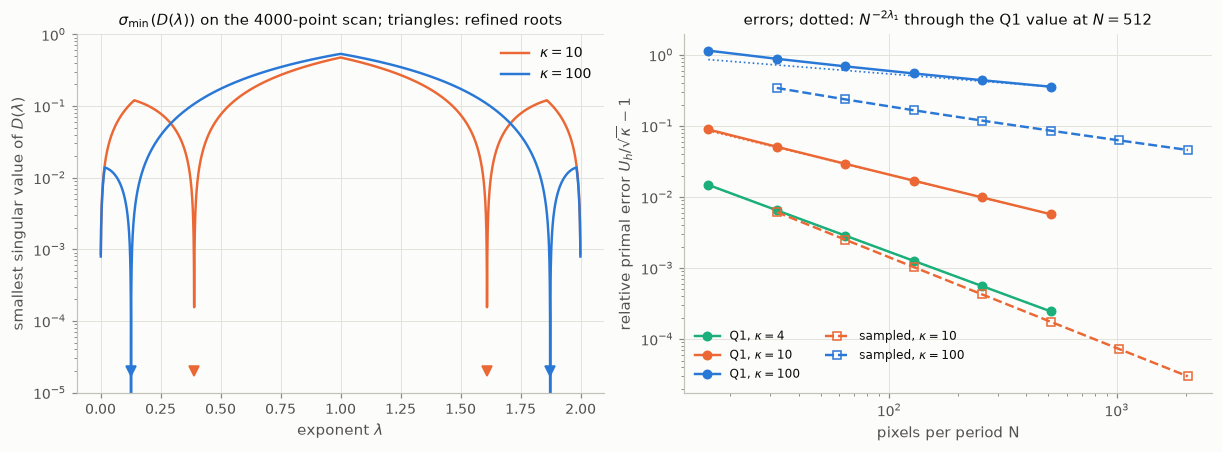

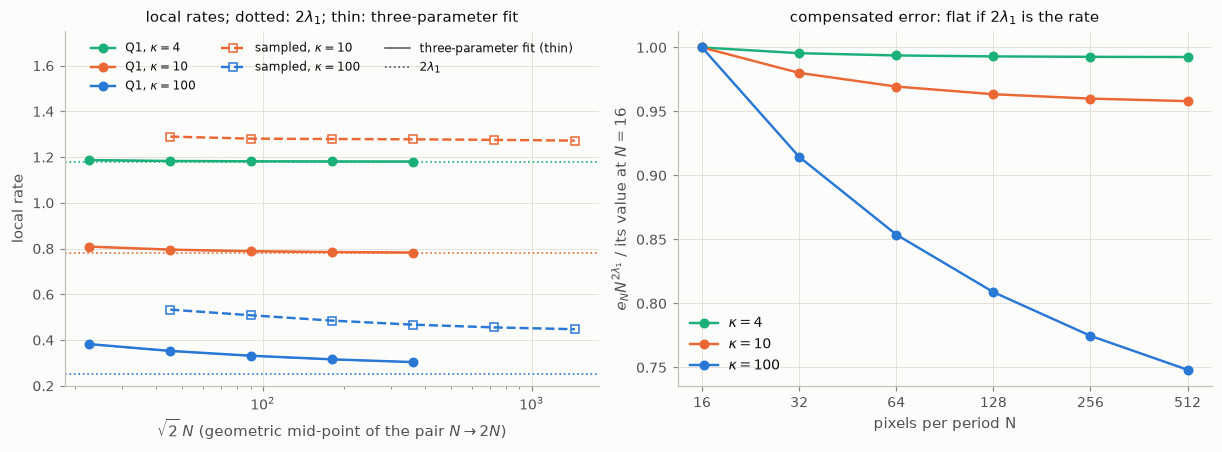

In [10]:
# figure 2: the corner scan and the errors
fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
for k, col in ((10.0, CAT[1]), (100.0, CAT[0])):
    sm = CORNER[k]["smin"]
    ax[0].semilogy(LAM_GRID, sm, color=col, label=rf"$\kappa={k:g}$")
    for r_ in CORNER[k]["roots"]:
        ax[0].plot(r_[0], 2e-5, marker="v", color=col, ms=7)
ax[0].set_xlabel(r"exponent $\lambda$"); ax[0].set_ylabel(r"smallest singular value of $D(\lambda)$")
ax[0].set_title(r"$\sigma_{\min}(D(\lambda))$ on the 4000-point scan; triangles: refined roots"); ax[0].set_ylim(1e-5, 1)
ax[0].legend()
Nf = np.array(NS, float)
for k, col in zip(KAPPAS, (CAT[2], CAT[1], CAT[0])):
    ax[1].loglog(Nf, E[k], "o-", color=col, label=rf"Q1, $\kappa={k:g}$")
    ax[1].loglog(Nf, E[k][-1] * (Nf / Nf[-1]) ** (-2 * LAM1[k]), ":", color=col, lw=1.1)
for k, col in ((10.0, CAT[1]), (100.0, CAT[0])):
    ax[1].loglog(MS_N, [MS[(k, N)][0] for N in MS_N], "s--", mfc="none", color=col, label=rf"sampled, $\kappa={k:g}$")
ax[1].set_xlabel("pixels per period N"); ax[1].set_ylabel(r"relative primal error $U_h/\sqrt{\kappa}-1$")
ax[1].set_title(r"errors; dotted: $N^{-2\lambda_1}$ through the Q1 value at $N=512$")
ax[1].legend(ncol=2, fontsize=8)
plt.show()

# figure 3: local rates and compensated errors
fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
for k, col in zip(KAPPAS, (CAT[2], CAT[1], CAT[0])):
    ax[0].semilogx(NC * np.sqrt(2), RATE[k], "o-", color=col, label=rf"Q1, $\kappa={k:g}$")
    ax[0].axhline(2 * LAM1[k], color=col, ls=":", lw=1.1)
    Ng = np.logspace(np.log10(NC[0]), np.log10(NC[-1]), 100)
    ax[0].semilogx(Ng * np.sqrt(2), FIT[k]["rinf"] + FIT[k]["c"] * Ng ** -FIT[k]["g"], "-", color=col, lw=1.0, alpha=0.9)
for k, col in ((10.0, CAT[1]), (100.0, CAT[0])):
    ax[0].semilogx(np.array(MS_N[:-1]) * np.sqrt(2), MS_RATE[k], "s--", mfc="none", color=col, label=rf"sampled, $\kappa={k:g}$")
ax[0].set_xlabel(r"$\sqrt{2}\,N$ (geometric mid-point of the pair $N\to 2N$)"); ax[0].set_ylabel("local rate")
ax[0].set_title(r"local rates; dotted: $2\lambda_1$; thin: three-parameter fit")
ax[0].plot([], [], "-", color=INK2, lw=1.0, label="three-parameter fit (thin)"); ax[0].plot([], [], ":", color=INK2, lw=1.1, label=r"$2\lambda_1$")
ax[0].set_ylim(0.2, 1.75); ax[0].legend(ncol=3, fontsize=8, loc="upper center")
for k, col in zip(KAPPAS, (CAT[2], CAT[1], CAT[0])):
    comp = E[k] * Nf ** (2 * LAM1[k])
    ax[1].semilogx(Nf, comp / comp[0], "o-", color=col, label=rf"$\kappa={k:g}$")
ax[1].set_xlabel("pixels per period N"); ax[1].set_ylabel(r"$e_N N^{2\lambda_1}$ / its value at $N=16$")
ax[1].set_title(r"compensated error: flat if $2\lambda_1$ is the rate"); ax[1].legend()
ax[1].set_xticks(NS); ax[1].set_xticklabels([str(n) for n in NS]); ax[1].minorticks_off()
plt.show()

*Figure 2.* Left: the smallest singular value of $D$ on the scan grid; the triangles mark the refined roots (each case has exactly two in the interval). Right: relative primal errors of the Q1 pair (filled) and of the sampled scheme (open), with $N^{-2\lambda_1}$ drawn through the last Q1 value. *Figure 3.* Left: local rates, with $2\lambda_1$ dotted and the three-parameter fit thin. Right: the compensated error, normalized to its value at $N=16$.

Reading the printed outcomes.

- **Roots.** The numerical roots agree with the closed form for both branches to the rounding level; the closed-form values give singular values at the rounding unit, and $\lambda=2$ is a root as stated.
- **Q1 rates, $\kappa=4$ and $10$.** The local rates decrease strictly and stay above $2\lambda_1$, with the last ones within $2\times10^{-4}$ and $3\times10^{-3}$ of it. The fitted $r_\infty$ differs from $2\lambda_1$ by $7\times10^{-5}$ and $6\times10^{-4}$, and the compensated error changes by $-0.01\%$ and $-0.21\%$ over the last octave ($256\to512$; $-0.03\%$ and $-0.36\%$ over the octave before). At $\kappa=4$ the leave-one-out and $g$-profile spreads of $r_\infty$ reach down to $2\lambda_1$ to the digits printed; at $\kappa=10$ they run from $0.7802$ to $0.7809$, so $2\lambda_1=0.7799$ lies $3\times10^{-4}$ below the lowest of them: the fit is within $10^{-3}$ of $2\lambda_1$ but its own spread excludes it. The power-law form describes these two contrasts better than the logarithmic one (rms residual ratio $3.6$ or more in all three cases), and the logarithmic extrapolations lie below $2\lambda_1$ by $0.007$ and $0.025$. The observations are consistent with the corner theory where the rates are close to asymptotic; they do not verify it to the printed digits.
- **Q1 rate, $\kappa=100$ is pre-asymptotic and the limit is not pinned.** All five local rates exceed $2\lambda_1=0.2538$, they decrease strictly, and the last is $0.050$ above it. On the Q1 data alone the power-law fit puts the limit above $2\lambda_1$: $r_\infty=0.272$, with leave-one-out range $0.267$ to $0.276$ and $g$-profile range $0.267$ to $0.276$, so $2\lambda_1$ lies $0.014$ below the lowest refit. Only the corner theory ($e_N=O(N^{-2\lambda_1})$) together with the pre-asymptotic scale $N^*=e^{1/\lambda_1}\approx2.6\times10^3$, far beyond the $N=512$ reached, argues that the limit is $2\lambda_1$ and that the five rates are not yet in the power-law regime. The logarithmic ansatz ($r_\infty=0.226$, $0.0275$ below $2\lambda_1$) is a device for seeing how much the extrapolation depends on the functional form; it has no theoretical basis, fits worse than the power law (rms $7.4\times10^{-4}$ against $2.0\times10^{-4}$), and is not evidence for any limit. The compensated error is still falling by $3.4\%$ per octave ($256\to512$; $4.2\%$ over the octave before). So the data neither verify nor refute $2\lambda_1$ at $\kappa=100$; they point somewhat above it, and the theory-based expectation rests on an asymptotic regime not reached here (the fit uses $3$ parameters on $5$ points, with $g$ profiled).
- **Sampled scheme.** At $\kappa=10$ its error is positive and decreasing, $0.043$ of the Q1 error at $N=256$, with the local rate staying within $1.27$ to $1.29$ from $N=32$ to $2048$ and drifting down by about $0.02$ in total; it does not settle to a limit. The value $2\lambda_1+\tfrac12=1.280$ lies inside this band (the last rate is within $0.008$ of it), but at $\kappa=100$ the rates fall from $0.53$ to $0.45$ and are still decreasing, already below $4\lambda_1=0.51$ and far from $2\lambda_1+\tfrac12=0.75$. So no single one of the three candidates describes both contrasts, and none is claimed. The PCG iteration count grows by a factor of only $1.1$ ($\kappa=10$) and $1.4$ ($\kappa=100$) from $N=64$ to $512$, as spectral equivalence of the preconditioner predicts. Positivity of the sampled error is an observation on this geometry, not a theorem.

## 4. Disks: a certified bracket on the true geometry

A pixel disk is a staircase, a different object from the disk. For the true disk of radius $R$ centered in the cell, with conductivity $s_{\rm in}$ inside and $s_{\rm out}$ outside and area fraction $f=\pi R^2$, the Fourier coefficients of $\sigma$ are known in closed form,

$$\hat\sigma(k)=s_{\rm out}\,\delta_{k0}+(s_{\rm in}-s_{\rm out})\,f\,\frac{2J_1(|k|R)}{|k|R}\,e^{-ik\cdot c},\qquad k=2\pi(n_x,n_y).$$

Let $\mathcal T_K$ be the real trigonometric polynomials of degree at most $K$ in each coordinate. The Galerkin form $\langle\sigma\nabla\varphi\cdot\nabla\psi\rangle$ on $\mathcal T_K$ involves $\hat\sigma$ only up to degree $2K$, so it is *exact* for the true disk, with no geometric error. It is applied by zero-padded FFT on an $M\times M$ grid with $M=4K+2$, which prevents aliasing into $|k|\le K$. The primal minimum over $\mathcal T_K\subset H^1_{\rm per}$ is a rigorous upper bound $U_K$ for the true disk; the stream-function dual (the same shape with coefficients of $1/\sigma$, direction swapped) gives a rigorous lower bound $L_K$. Both are monotone in $K$ (nested spaces). Each bound is evaluated as the exact energy of the final conjugate-gradient iterate, so it is a bound even if the iteration is stopped early (the bounds are then wider); the notebook asserts convergence anyway. Rounding is of order $10^{-13}$. Since a disk has a gradient jump across a smooth curve, a trigonometric polynomial approximates the corrector's gradient in $L^2$ at best like $K^{-1/2}$, so the energy gap should close like $1/K$.

The exact reference is the Rayleigh multipole value for the square array (Rayleigh 1892; Perrins, McKenzie and McPhedran 1979 for the numerical treatment): with $\beta=(\kappa-1)/(\kappa+1)$ and the real symmetric matrix $W_{lm}=\sqrt{l/m}\,R^{l+m}\big[\pi\delta_{l1}\delta_{m1}+\binom{l+m-1}{l}S_{l+m}\mathbf 1_{l+m\ge4}\big]$ over odd orders, $\sigma^*/s_{\rm out}=1+2f[(I/\beta-W)^{-1}]_{11}$, with $S_n$ the Eisenstein sums of the square lattice ($S_4=\Gamma(1/4)^8/(960\pi^2)$, $S_n=0$ unless $4\mid n$). The $(1,1)$ slot carries $\pi$, so $W_{11}=f$ and truncation at one order is exactly Maxwell Garnett. It converges exponentially in the multipole order and is not certified. It shares no code with the Fourier-Galerkin solver, but its value at $(0.5,10)$ is compared below only against a number from an earlier run of the same algorithm; the independent evidence is the Fourier-Galerkin bracket and its $1/K$ extrapolation. Also printed: Hashin-Shtrikman (1962), Maxwell Garnett (equal to the HS lower bound in 2D when the disks are the stronger phase), Bruggeman and Wiener values.

*Computations.* (i) Square arrays of disks at $(f,\kappa)=(0.5,10)$, $(0.5,100)$ and $(\pi\,0.3^2,12)$; the last is the TE static permittivity of the rods of the spatial-dispersion notebooks, with the permittivity in the role of $\sigma$. The Rayleigh value at $L=5,10,20$ against the series $1+2f/(1/\beta-f-c_4\beta f^4-c_8\beta f^8)$ used there and the dilute limit. (ii) Fourier-Galerkin brackets for $K=8,\dots,128$ (the FFT-based Galerkin method with guaranteed bounds of Vondrejc, Zeman and Marek 2015, here with exact Fourier coefficients of the disk; preconditioned conjugate gradients as in Zeman et al. 2010). (iii) Center-sampled pixel disks, $N=64,128,256$: strong disks (phase $10$ in $1$, $f=0.5$) and weak disks (phase $1$ in $10$, $f=0.5$ and $0.7$), compared with the Rayleigh value at the true area fraction $f$ and at the pixel area fraction $f_{\rm pix}$; then the fixed $N=64$ and $128$ staircases solved on finer meshes (each pixel split into $m\times m$ sub-pixels, with $m=4$ and $2$, so that both reach $N=256$ for the solver), which leaves the pixel medium unchanged and narrows the bracket by the solver error only.

In [11]:
t_sec = time.perf_counter()
# Section 4. Disks. Case = (label, f, kappa); the host has conductivity 1, the disk of radius sqrt(f/pi) has conductivity kappa
CASES = [("(0.5, 10)", 0.5, 10.0), ("(0.5, 100)", 0.5, 100.0), ("(pi 0.3^2, 12)", np.pi * 0.3 ** 2, 12.0)]
RAY = {}
print(f"{'(f, kappa)':>15s} {'sigma(L=5)':>14s} {'sigma(L=10)':>14s} {'sigma(L=20)':>14s} {'|s20/s10 - 1|':>14s}")
for lab, f, kap in CASES:
    sg = {L_: float(ry.sigma_eff(f, kap, L=L_)) for L_ in (5, 10, 20)}
    RAY[lab] = sg[20]
    print(f"{lab:>15s} {sg[5]:14.10f} {sg[10]:14.10f} {sg[20]:14.10f} {abs(sg[20] / sg[10] - 1):14.1e}")
    check(f"Rayleigh converged in the multipole order, {lab}: |sigma(20)/sigma(10) - 1|", abs(sg[20] / sg[10] - 1), 1e-11)
check("Rayleigh at (0.5, 10) against the value 2.4154673802 recorded from an earlier run of the same multipole algorithm (a self-consistency check, not independent)", RAY["(0.5, 10)"], 1e-9, 2.4154673802)
# the series of notebook 03 of spatial_dispersion, 1 + 2f / (1/b - f - c4 b f^4 - c8 b f^8), eps = 12 (constants as recorded there)
f12, b12 = np.pi * 0.3 ** 2, 11.0 / 13.0
ser12 = 1 + 2 * f12 / (1 / b12 - f12 - 0.305827 * b12 * f12 ** 4 - 0.013362 * b12 * f12 ** 8)
print(f"series of spatial_dispersion notebook 03 at eps = 12: {ser12:.10f};  Rayleigh L = 20: {RAY['(pi 0.3^2, 12)']:.10f}")
check("Rayleigh at eps = 12 against that series", RAY["(pi 0.3^2, 12)"], 1e-7, ser12)
S4 = ry.square_lattice_sums(8)[4]
print(f"3 S_4^2 / pi^4 from the lattice sum: {3 * S4 ** 2 / np.pi ** 4:.9f}")
check("the series constant 3 S_4^2 / pi^4 against the six-digit constant 0.305827 recorded (truncated) in spatial-dispersion notebook 03; tolerance 1e-6 = one unit of the sixth digit", 3 * S4 ** 2 / np.pi ** 4, 1e-6, 0.305827)
# dilute limit: Maxwell Garnett plus the first lattice correction
f_d, k_d = 0.01, 10.0
sig_d, mg_d = float(ry.sigma_eff(f_d, k_d)), bd.maxwell_garnett2d(k_d, 1.0, f_d)
b_ = (k_d - 1) / (k_d + 1)
pred = (1 + 2 * f_d / (1 / b_ - f_d - 3 * S4 ** 2 / np.pi ** 4 * b_ * f_d ** 4)) / mg_d - 1
print(f"dilute limit f = 0.01, kappa = 10: sigma/sigma_MG - 1 = {sig_d / mg_d - 1:.4e};  first lattice correction (3 S4^2/pi^4) beta f^4 predicts {pred:.4e}")
check("first lattice correction: ratio of observed to predicted deviation from Maxwell Garnett", (sig_d / mg_d - 1) / pred, 1e-2, 1.0)
# Hashin-Shtrikman and Maxwell Garnett
for lab, f, kap in CASES:
    lo, hi = bd.hs2d(1.0, kap, 1 - f)
    mg = bd.maxwell_garnett2d(kap, 1.0, f)
    check_in(f"HS contains the Rayleigh value, {lab}  [{lo:.6f}, {hi:.6f}]", RAY[lab], lo, hi)
    check(f"Maxwell Garnett equals the HS lower bound (disks in the weaker host), {lab}", mg, 1e-14, lo)
    print(f"      {lab}: Rayleigh {RAY[lab]:.6f},  MG = HS_lo {mg:.6f},  HS_up {hi:.6f},  Bruggeman {bd.bruggeman2d(1.0, kap, 1 - f):.6f},  Wiener [{bd.wiener(1.0, kap, 1 - f)[0]:.4f}, {bd.wiener(1.0, kap, 1 - f)[1]:.4f}]")
SEC["4a"] = time.perf_counter() - t_sec

     (f, kappa)     sigma(L=5)    sigma(L=10)    sigma(L=20)  |s20/s10 - 1|
      (0.5, 10)   2.4154672831   2.4154673802   2.4154673802        2.0e-14
PASS  Rayleigh converged in the multipole order, (0.5, 10): |sigma(20)/sigma(10) - 1|: got 2.02061e-14, target 0, |diff| 2.02e-14 <= 1e-11
     (0.5, 100)   2.9947674821   2.9947677390   2.9947677390        5.7e-14
PASS  Rayleigh converged in the multipole order, (0.5, 100): |sigma(20)/sigma(10) - 1|: got 5.68434e-14, target 0, |diff| 5.68e-14 <= 1e-11
 (pi 0.3^2, 12)   1.6301245629   1.6301245630   1.6301245630        0.0e+00
PASS  Rayleigh converged in the multipole order, (pi 0.3^2, 12): |sigma(20)/sigma(10) - 1|: got 0, target 0, |diff| 0.00e+00 <= 1e-11
PASS  Rayleigh at (0.5, 10) against the value 2.4154673802 recorded from an earlier run of the same multipole algorithm (a self-consistency check, not independent): got 2.41547, target 2.41547, |diff| 1.28e-11 <= 1e-09
series of spatial_dispersion notebook 03 at eps = 12: 1.63012451

In [12]:
t_sec = time.perf_counter()
KS = (8, 16, 32, 64, 128)
FG = {}
for lab, f, kap in CASES:
    R_ = np.sqrt(f / np.pi)
    for K in KS:
        t_ = time.perf_counter()
        Lk, Uk, info = cs.fg_bracket("disk", K, R=R_, s_in=kap, s_out=1.0)
        assert info["converged"], (lab, K, info)
        FG[(lab, K)] = (Lk, Uk, info["iterations"], time.perf_counter() - t_)
print(f"{'case':>15s} {'K':>4s} {'L_K':>10s} {'U_K':>10s} {'U_K - L_K':>10s} {'iters (primal, dual)':>21s} {'seconds':>8s}   Rayleigh")
for lab, f, kap in CASES:
    for K in KS:
        Lk, Uk, its, dt = FG[(lab, K)]
        print(f"{lab:>15s} {K:4d} {Lk:10.6f} {Uk:10.6f} {Uk - Lk:10.6f} {str(its):>21s} {dt:8.2f}   {RAY[lab]:.6f}")
slack_in = min(min(RAY[lab] - FG[(lab, K)][0], FG[(lab, K)][1] - RAY[lab]) for lab, _, _ in CASES for K in KS)
check_in("FG bracket contains the Rayleigh value, all 3 cases and 5 K (smallest margin)", slack_in, -1e-12, np.inf)
mono_U = min(FG[(lab, KS[i])][1] - FG[(lab, KS[i + 1])][1] for lab, _, _ in CASES for i in range(4))
mono_L = min(FG[(lab, KS[i + 1])][0] - FG[(lab, KS[i])][0] for lab, _, _ in CASES for i in range(4))
check_in("U_K non-increasing in K (smallest decrease)", mono_U, -1e-12, np.inf)
check_in("L_K non-decreasing in K (smallest increase)", mono_L, -1e-12, np.inf)
SLOPE = {}
for lab, f, kap in CASES:
    Ks = np.array(KS[1:], float)
    w = np.array([FG[(lab, K)][1] - FG[(lab, K)][0] for K in KS[1:]])
    SLOPE[lab] = np.polyfit(np.log(Ks), np.log(w), 1)[0]
    ex_U = 2 * FG[(lab, 128)][1] - FG[(lab, 64)][1]
    ex_L = 2 * FG[(lab, 128)][0] - FG[(lab, 64)][0]
    mid64 = 0.5 * (FG[(lab, 64)][0] + FG[(lab, 64)][1])
    mid128 = 0.5 * (FG[(lab, 128)][0] + FG[(lab, 128)][1])
    print(f"{lab:>15s}: slope of log(U-L) vs log K over K = 16 ... 128: {SLOPE[lab]:+.3f};  1/K-extrapolated bounds [{ex_L:.5f}, {ex_U:.5f}] vs Rayleigh {RAY[lab]:.5f}"
          f" (rel. {ex_L / RAY[lab] - 1:+.1e}, {ex_U / RAY[lab] - 1:+.1e});  midpoint error K=64: {mid64 / RAY[lab] - 1:+.2e}, K=128: {mid128 / RAY[lab] - 1:+.2e}")
    check_in(f"bracket closes like 1/K, {lab}: slope of log width vs log K", SLOPE[lab], -1.15, -0.85)
lab0 = "(0.5, 10)"
for lab_x, _, _ in CASES:
    for nm, val in (("upper", 2 * FG[(lab_x, 128)][1] - FG[(lab_x, 64)][1]), ("lower", 2 * FG[(lab_x, 128)][0] - FG[(lab_x, 64)][0])):
        check_in(f"{nm} bound extrapolated linearly in 1/K from K = 64, 128, relative to Rayleigh at {lab_x} (window set after seeing)", val / RAY[lab_x] - 1, -5e-4, 5e-4)
mid64 = 0.5 * (FG[(lab0, 64)][0] + FG[(lab0, 64)][1])
check_in("the K = 64 midpoint of the certified bracket is biased high at (0.5, 10) (relative error)", mid64 / RAY[lab0] - 1, 1e-3, np.inf)
print("\none-sided distances to the Rayleigh value at K = 128 (the bracket is not centered on the truth):")
ratio_k = {}
for lab, f, kap in CASES:
    du, dl = FG[(lab, 128)][1] - RAY[lab], RAY[lab] - FG[(lab, 128)][0]
    ratio_k[lab] = du / dl / kap
    print(f"  {lab:>15s}: U - sigma = {du:.3e}, sigma - L = {dl:.3e}, ratio {du / dl:7.2f} = {ratio_k[lab]:.3f} kappa")
check_in("ratio (U - sigma)/(sigma - L) over kappa at K = 128, smallest of the 3 cases (range set after seeing the table)", min(ratio_k.values()), 0.9, 1.2)
check_in("ratio (U - sigma)/(sigma - L) over kappa at K = 128, largest of the 3 cases", max(ratio_k.values()), 0.9, 1.2)
SEC["4b"] = time.perf_counter() - t_sec

           case    K        L_K        U_K  U_K - L_K  iters (primal, dual)  seconds   Rayleigh
      (0.5, 10)    8   2.400875   2.581203   0.180328              (35, 35)     0.01   2.415467
      (0.5, 10)   16   2.408174   2.494377   0.086203              (42, 41)     0.02   2.415467
      (0.5, 10)   32   2.411771   2.454969   0.043198              (42, 41)     0.08   2.415467
      (0.5, 10)   64   2.413617   2.435077   0.021461              (43, 41)     0.19   2.415467
      (0.5, 10)  128   2.414539   2.425261   0.010722              (43, 42)     1.22   2.415467
     (0.5, 100)    8   2.989306   3.728597   0.739292              (55, 46)     0.01   2.994768
     (0.5, 100)   16   2.992018   3.315990   0.323972              (87, 82)     0.07   2.994768
     (0.5, 100)   32   2.993404   3.146081   0.152676            (128, 121)     0.27   2.994768
     (0.5, 100)   64   2.994086   3.068614   0.074528            (130, 126)     0.60   2.994768
     (0.5, 100)  128   2.994427   3.0312

Reading the printed outcomes of (i) and (ii).

- **Reference.** The Rayleigh value is converged in the multipole order to rounding, reproduces $2.4154673802$ at $(0.5,10)$ (a self-consistency check against an earlier run of the same algorithm, not an independent value), matches the series of spatial-dispersion notebook 03 at $\varepsilon=12$ to $5\times10^{-8}$ (the series shares the lattice sums, and its six-digit constant $c_4=0.305827$ there is a truncation of $3S_4^2/\pi^4=0.305827833$), and in the dilute limit it deviates from Maxwell Garnett by the predicted first lattice correction (the ratio of observed to predicted deviation is $1$ to the digits shown; the deviation is only $3.4\times10^{-11}$). All three values lie inside the Hashin-Shtrikman interval, and Maxwell Garnett equals the HS lower bound to $4\times10^{-16}$. Independent confirmation of the Rayleigh value comes from the Fourier-Galerkin bracket (rigorous to about $10^{-3}$ at $K=128$) and its $1/K$ extrapolation (about $10^{-5}$ at $(0.5,10)$ and $(\pi\,0.3^2,12)$).
- **The bracket is rigorous and closes like $1/K$.** Every bracket contains the Rayleigh value, $U_K$ decreases and $L_K$ increases, the log-log slope of the width over $K=16,\dots,128$ is $-1.003$, $-1.045$ and $-1.000$ in the three cases, and all conjugate-gradient runs converged.
- **The midpoint is biased.** The one-sided distances are not equal: $U_K-\sigma^*$ is $1.016$ to $1.071$ times $\kappa$ times $\sigma^*-L_K$ at $K=128$. Both converge like $1/K$, but with constants a factor of about $\kappa$ apart, so the midpoint of the certified interval is off by $3.7\times10^{-3}$ at $K=64$ and $(0.5,10)$ (half of that at $K=128$) and should not be used as an estimate. The factor-$\kappa$ ratio is an observation over three cases, all with disks stronger than the host; no derivation is offered and nothing is claimed for weaker disks.
- **Extrapolation.** Extrapolating each bound linearly in $1/K$ from $K=64$ and $128$ gives values within $9\times10^{-6}$ of the Rayleigh value at $(0.5,10)$ and within $2\times10^{-6}$ at $(\pi\,0.3^2,12)$. At $(0.5,100)$ the extrapolated lower bound is within $3\times10^{-7}$ but the upper bound is $2.9\times10^{-4}$ below the Rayleigh value, so there the extrapolation overshoots and is not a safe estimate. All of these are within the post hoc tolerance $5\times10^{-4}$. This is a convergence statement about the Fourier-Galerkin sequence, not a certificate.

**Staircase disks.** The pixel bracket brackets $\sigma^*$ of the staircase medium. The natural conjecture, recorded in `PLAN.md` before the computation, was that the staircase disk differs from the true disk mainly through its area (a pixel disk has area fraction $f_{\rm pix}\neq f$). Write $\sigma_h-R(f)=[R(f_{\rm pix})-R(f)]+[\sigma_{\rm stair}-R(f_{\rm pix})]$, with $R$ the Rayleigh value: an area part and a shape part. The pixel bracket certifies the shape part wherever it excludes $R(f_{\rm pix})$. As $N\to\infty$ the staircase converges to the disk, so any shape effect must vanish with $N$; the questions are how it compares with the area part at the sizes used and what the certified intervals say about its decay. The table below reports the position of $R(f_{\rm pix})$ relative to the pixel bracket and the decomposition.

In [13]:
t_sec = time.perf_counter()
# Staircase (center-sampled pixel) disks: certified bracket on the pixel medium against the Rayleigh values at the true area fraction f
# and at the pixel area fraction f_pix. Strong disks: phase 10 in host 1. Weak disks: phase 1 in host 10 (kappa_disk/kappa_host = 0.1).
def rayleigh_val(f, a_in, a_out):
    return a_out * float(ry.sigma_eff(f, a_in / a_out, L=40))

STAIR = {}
for name, f, a_in, a_out in (("strong, f = 0.5", 0.5, 10.0, 1.0), ("weak, f = 0.5", 0.5, 1.0, 10.0), ("weak, f = 0.7", 0.7, 1.0, 10.0)):
    R_ = np.sqrt(f / np.pi)
    for N in (64, 128, 256):
        s = cs.disk_pixels(N, R_, a_in, a_out)
        fpix = float(np.mean(s == a_in))
        Lh, Uh = cs.q1_bracket(s)
        STAIR[(name, N)] = dict(f=f, fpix=fpix, L=Lh[0, 0], U=Uh[0, 0], R_true=rayleigh_val(f, a_in, a_out), R_pix=rayleigh_val(fpix, a_in, a_out))
print(f"{'disks':>16s} {'N':>4s} {'f_pix':>8s} {'L_h':>9s} {'U_h':>9s} {'R(f)':>9s} {'R(f_pix)':>9s} {'(R(f_pix)-U_h)/R':>17s} {'position of R(f_pix)':>22s}")
for (name, N), d in STAIR.items():
    pos = "above the bracket" if d["R_pix"] > d["U"] else ("below the bracket" if d["R_pix"] < d["L"] else "inside the bracket")
    d["pos"] = pos
    print(f"{name:>16s} {N:4d} {d['fpix']:8.5f} {d['L']:9.5f} {d['U']:9.5f} {d['R_true']:9.5f} {d['R_pix']:9.5f} {(d['R_pix'] - d['U']) / d['R_pix']:17.2e} {pos:>22s}")

# area part and shape part of the departure of the staircase from the true disk: sigma_h - R(f) = [R(f_pix) - R(f)] + [sigma_h - R(f_pix)]
print("\ndecomposition relative to R(f_pix): area part (R(f_pix) - R(f))/R(f_pix); shape part bracket [(L_h - R(f_pix))/R(f_pix), (U_h - R(f_pix))/R(f_pix)]")
print(f"{'disks':>16s} {'N':>4s} {'area part':>11s} {'shape, lower':>13s} {'shape, upper':>13s}")
for (name, N), d in STAIR.items():
    print(f"{name:>16s} {N:4d} {(d['R_pix'] - d['R_true']) / d['R_pix']:+11.2e} {(d['L'] - d['R_pix']) / d['R_pix']:+13.2e} {(d['U'] - d['R_pix']) / d['R_pix']:+13.2e}")

# the two f = 0.5 families are Keller twins: the weak pixel field is the phase swap of the strong one (a unit test of the identity, no new information)
tw = max(abs(STAIR[("weak, f = 0.5", N)]["L"] * STAIR[("strong, f = 0.5", N)]["U"] / 10.0 - 1) for N in (64, 128, 256))
check("strong and weak pixel disks at f = 0.5 are interchange twins: L_h[weak] U_h[strong] = ab (worst over N)", tw, 1e-10)
for (name, N), d in STAIR.items():
    d["dist"] = max(d["R_pix"] - d["U"], d["L"] - d["R_pix"]) / d["R_pix"]       # > 0: the bracket excludes R(f_pix), by this relative distance
    d["excl"] = d["dist"] > 0
    d["shape_min"] = max(d["dist"], 0.0)
    d["shape_max"] = max(abs(d["L"] - d["R_pix"]), abs(d["U"] - d["R_pix"])) / d["R_pix"]       # the shape part is at most this large
    d["area"] = abs(d["R_pix"] - d["R_true"]) / d["R_pix"]
print("\ncertified: the bracket excludes R(f_pix) in", sum(d["excl"] for d in STAIR.values()), "of 9 cases;",
      "the exception:", [k for k, d in STAIR.items() if not d["excl"]])
check_in("weak disks f = 0.5, N = 128: R(f_pix) minus U_h is positive (the bracket excludes it)", STAIR[("weak, f = 0.5", 128)]["R_pix"] - STAIR[("weak, f = 0.5", 128)]["U"], 1e-12, np.inf)
check_in("f = 0.5, both families, N = 64, 128, 256: smallest relative distance of R(f_pix) from the bracket", min(
    d["dist"] for (nm, N), d in STAIR.items() if nm.endswith("f = 0.5")), 1e-12, np.inf)
check_in("weak disks f = 0.7, N = 128: R(f_pix) lies inside the bracket (the one case not excluded)", float(STAIR[("weak, f = 0.7", 128)]["excl"]), 0.0, 0.0)
# the certified endpoints of the shape-part interval, f = 0.5 (the strong and weak families are twins and give the same numbers)
for nm in ("strong, f = 0.5", "weak, f = 0.5"):
    m = [STAIR[(nm, N)]["shape_min"] for N in (64, 128, 256)]
    x = [STAIR[(nm, N)]["shape_max"] for N in (64, 128, 256)]
    print(f"{nm}: certified magnitude of the shape part, lower end {m[0]:.2e}, {m[1]:.2e}, {m[2]:.2e}; upper end {x[0]:.2e}, {x[1]:.2e}, {x[2]:.2e}")
    check_in(f"{nm}: lower end of the certified shape magnitude falls by a factor in [2, 3] per doubling (64 -> 128; window set after seeing)", m[0] / m[1], 2.0, 3.0)
    check_in(f"{nm}: ... (128 -> 256)", m[1] / m[2], 2.0, 3.0)
    check_in(f"{nm}: upper end of the certified shape magnitude falls by a factor in [1.8, 2.8] per doubling (64 -> 128; window set after seeing)", x[0] / x[1], 1.8, 2.8)
    check_in(f"{nm}: ... (128 -> 256)", x[1] / x[2], 1.8, 2.8)
# weak f = 0.7: the certified shape part is not monotone in N
sh7 = {N: ((STAIR[("weak, f = 0.7", N)]["L"] - STAIR[("weak, f = 0.7", N)]["R_pix"]) / STAIR[("weak, f = 0.7", N)]["R_pix"],
           (STAIR[("weak, f = 0.7", N)]["U"] - STAIR[("weak, f = 0.7", N)]["R_pix"]) / STAIR[("weak, f = 0.7", N)]["R_pix"]) for N in (64, 128, 256)}
check_in("weak f = 0.7: certified distance of R(f_pix) from the bracket is larger at N = 256 than at N = 64 (ratio; observed, no monotone decay)",
         STAIR[("weak, f = 0.7", 256)]["shape_min"] / STAIR[("weak, f = 0.7", 64)]["shape_min"], 1.0, np.inf)
check_in("weak f = 0.7: the N = 128 and N = 256 shape intervals overlap (largest lower end minus smallest upper end; consistent with one constant)",
         max(sh7[128][0], sh7[256][0]) - min(sh7[128][1], sh7[256][1]), -np.inf, 0.0)
# shape against area part: the area part changes sign, so ratios at one N depend on a chance small area part
print("\nsign of the area part and certified shape/area ratios (lower end / upper end of the shape magnitude, over |area part|):")
for (name, N), d in STAIR.items():
    d["asign"] = np.sign(d["R_pix"] - d["R_true"])
    print(f"{name:>16s} {N:4d}  area part {d['asign'] * d['area']:+.2e}   shape/area: {d['shape_min'] / d['area']:6.2f} .. {d['shape_max'] / d['area']:6.2f}")
for nm in ("strong, f = 0.5", "weak, f = 0.5"):
    sg = [STAIR[(nm, N)]["asign"] for N in (64, 128, 256)]
    check_in(f"{nm}: the area part changes sign between consecutive N (largest product of consecutive signs)", max(sg[0] * sg[1], sg[1] * sg[2]), -np.inf, -1.0)

# refinement test: the same staircase medium solved on a finer mesh (each pixel split into m x m sub-pixels). The pixel medium is unchanged, so the
# bracket narrows by the solver error only and the shape part of that fixed staircase is certified more tightly.
REF = {}
print("\nfixed staircase, finer solver mesh (N0 pixels replicated m x m): shape-part bracket [(L-R(f_pix))/R(f_pix), (U-R(f_pix))/R(f_pix)]")
for name, f, a_in, a_out in (("strong, f = 0.5", 0.5, 10.0, 1.0), ("weak, f = 0.7", 0.7, 1.0, 10.0)):
    for N0, m_ in ((64, 4), (128, 2)):
        s0 = cs.disk_pixels(N0, np.sqrt(f / np.pi), a_in, a_out)
        Lr, Ur = cs.q1_bracket(np.kron(s0, np.ones((m_, m_))))
        d0 = STAIR[(name, N0)]
        REF[(name, N0)] = (Lr[0, 0], Ur[0, 0])
        print(f"{name:>16s} N0 = {N0:3d} on N = {N0 * m_:3d}:  [{(Lr[0, 0] - d0['R_pix']) / d0['R_pix']:+.2e}, {(Ur[0, 0] - d0['R_pix']) / d0['R_pix']:+.2e}]   (on N = {N0}: [{(d0['L'] - d0['R_pix']) / d0['R_pix']:+.2e}, {(d0['U'] - d0['R_pix']) / d0['R_pix']:+.2e}])")
        check_in(f"{name}, N0 = {N0}: the refined bracket lies inside the coarse bracket (smallest margin)", min(Lr[0, 0] - d0["L"], d0["U"] - Ur[0, 0]), -1e-12, np.inf)
        rel = sorted(abs((x - d0["R_pix"]) / d0["R_pix"]) for x in (Lr[0, 0], Ur[0, 0]))
        REF[(name, N0)] += ((Lr[0, 0] - d0["R_pix"]) / d0["R_pix"], (Ur[0, 0] - d0["R_pix"]) / d0["R_pix"])
        print(f"{'':>16s} {'':>22s} shape magnitude / area part of that staircase: {(0.0 if REF[(name, N0)][2] * REF[(name, N0)][3] < 0 else rel[0]) / d0['area']:.2f} .. {rel[1] / d0['area']:.2f}")
# certified comparisons from the refined brackets
sr64, sr128 = REF[("strong, f = 0.5", 64)], REF[("strong, f = 0.5", 128)]
print(f"strong f = 0.5: refined shape part, N0 = 64: [{sr64[2]:.2e}, {sr64[3]:.2e}], N0 = 128: [{sr128[2]:.2e}, {sr128[3]:.2e}]; certified decrease factor at least {sr64[2] / sr128[3]:.2f}")
check_in("strong f = 0.5: certified decrease of the shape part of the fixed staircase from N0 = 64 to 128 (lower end at 64 over upper end at 128; at least 1)", sr64[2] / sr128[3], 1.0, np.inf)
wr128 = REF[("weak, f = 0.7", 128)]
w256 = STAIR[("weak, f = 0.7", 256)]
w256_min = abs(w256["U"] - w256["R_pix"]) / w256["R_pix"]          # all of the N = 256 shape interval is negative: smallest magnitude
print(f"weak f = 0.7: shape part of the N0 = 128 staircase lies in [{wr128[2]:.2e}, {wr128[3]:.2e}]; of the N0 = 256 staircase in [{sh7[256][0]:.2e}, {sh7[256][1]:.2e}]")
check_in("weak f = 0.7: the N0 = 256 staircase has a certified shape magnitude larger than that of the N0 = 128 staircase (smallest magnitude at 256 minus largest at 128; certified non-monotone)",
         w256_min - max(abs(wr128[2]), abs(wr128[3])), 0.0, np.inf)
SEC["4c"] = time.perf_counter() - t_sec

           disks    N    f_pix       L_h       U_h      R(f)  R(f_pix)  (R(f_pix)-U_h)/R   position of R(f_pix)
 strong, f = 0.5   64  0.49805   2.41501   2.43148   2.41547   2.40556         -1.08e-02      below the bracket
 strong, f = 0.5  128  0.50098   2.42419   2.43171   2.41547   2.42045         -4.65e-03      below the bracket
 strong, f = 0.5  256  0.49988   2.41634   2.42012   2.41547   2.41485         -2.18e-03      below the bracket
   weak, f = 0.5   64  0.49805   4.11272   4.14078   4.13999   4.15703          3.91e-03      above the bracket
   weak, f = 0.5  128  0.50098   4.11233   4.12509   4.13999   4.13147          1.54e-03      above the bracket
   weak, f = 0.5  256  0.49988   4.13203   4.13849   4.13999   4.14105          6.18e-04      above the bracket
   weak, f = 0.7   64  0.70215   2.42159   2.44214   2.46202   2.44380          6.78e-04      above the bracket
   weak, f = 0.7  128  0.69995   2.45619   2.46674   2.46202   2.46243         -1.75e-03     inside the 

 strong, f = 0.5 N0 =  64 on N = 256:  [+7.57e-03, +8.48e-03]   (on N = 64: [+3.93e-03, +1.08e-02])
PASS  strong, f = 0.5, N0 = 64: the refined bracket lies inside the coarse bracket (smallest margin): got 0.00553376, required in [-1e-12, inf]
                                        shape magnitude / area part of that staircase: 1.84 .. 2.06


 strong, f = 0.5 N0 = 128 on N = 256:  [+2.83e-03, +3.94e-03]   (on N = 128: [+1.55e-03, +4.65e-03])
PASS  strong, f = 0.5, N0 = 128: the refined bracket lies inside the coarse bracket (smallest margin): got 0.00171933, required in [-1e-12, inf]
                                        shape magnitude / area part of that staircase: 1.38 .. 1.92


   weak, f = 0.7 N0 =  64 on N = 256:  [-6.14e-03, -5.04e-03]   (on N = 64: [-9.09e-03, -6.78e-04])
PASS  weak, f = 0.7, N0 = 64: the refined bracket lies inside the coarse bracket (smallest margin): got 0.00720022, required in [-1e-12, inf]
                                        shape magnitude / area part of that staircase: 0.68 .. 0.82


   weak, f = 0.7 N0 = 128 on N = 256:  [-1.48e-03, +6.02e-05]   (on N = 128: [-2.53e-03, +1.75e-03])
PASS  weak, f = 0.7, N0 = 128: the refined bracket lies inside the coarse bracket (smallest margin): got 0.0025935, required in [-1e-12, inf]
                                        shape magnitude / area part of that staircase: 0.00 .. 8.81
strong f = 0.5: refined shape part, N0 = 64: [7.57e-03, 8.48e-03], N0 = 128: [2.83e-03, 3.94e-03]; certified decrease factor at least 1.92
PASS  strong f = 0.5: certified decrease of the shape part of the fixed staircase from N0 = 64 to 128 (lower end at 64 over upper end at 128; at least 1): got 1.92048, required in [1, inf]
weak f = 0.7: shape part of the N0 = 128 staircase lies in [-1.48e-03, 6.02e-05]; of the N0 = 256 staircase in [-4.63e-03, -2.30e-03]
PASS  weak f = 0.7: the N0 = 256 staircase has a certified shape magnitude larger than that of the N0 = 128 staircase (smallest magnitude at 256 minus largest at 128; certified non-monotone): got

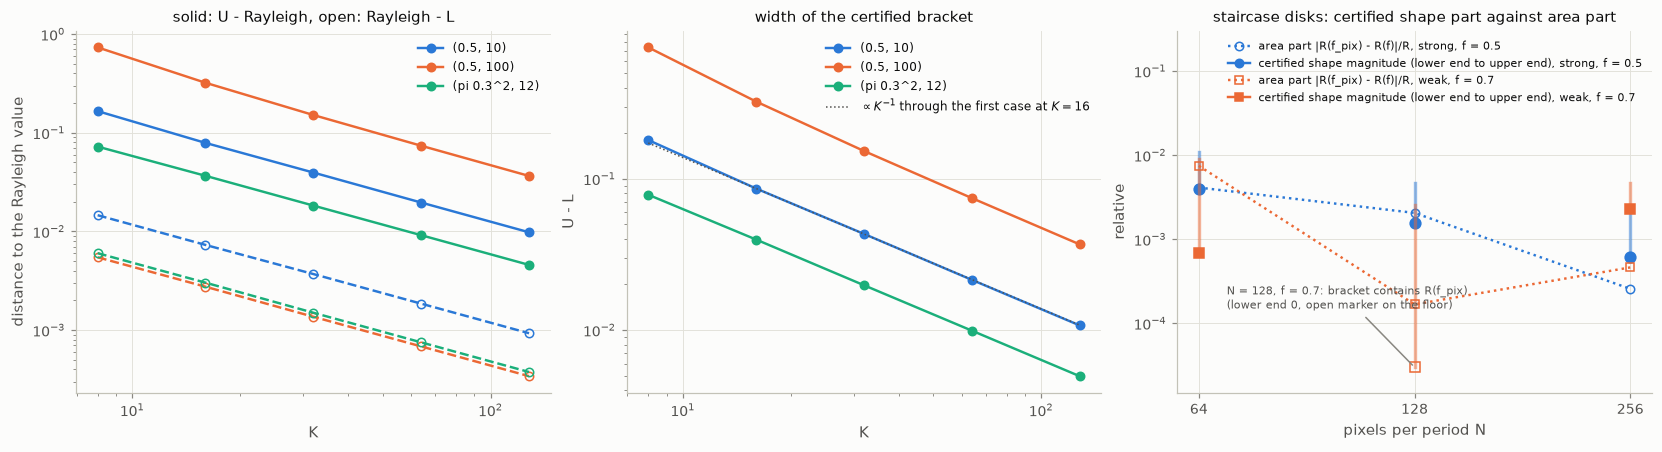

In [14]:
# figure 4: Fourier-Galerkin brackets for the true disk and the staircase
fig, ax = plt.subplots(1, 3, figsize=(15, 4.0))
for (lab, f, kap), col in zip(CASES, (CAT[0], CAT[1], CAT[2])):
    Kx = np.array(KS, float)
    ax[0].loglog(Kx, [FG[(lab, K)][1] - RAY[lab] for K in KS], "o-", color=col, label=f"{lab}")
    ax[0].loglog(Kx, [RAY[lab] - FG[(lab, K)][0] for K in KS], "o--", mfc="none", color=col)
    ax[1].loglog(Kx, [FG[(lab, K)][1] - FG[(lab, K)][0] for K in KS], "o-", color=col, label=f"{lab}")
ax[0].set_xlabel("K"); ax[0].set_ylabel("distance to the Rayleigh value"); ax[0].set_title("solid: U - Rayleigh, open: Rayleigh - L"); ax[0].legend(fontsize=8)
Kx = np.array(KS, float)
w16 = FG[(CASES[0][0], 16)][1] - FG[(CASES[0][0], 16)][0]
ax[1].loglog(Kx, w16 * (Kx / 16.0) ** -1.0, ":", color=INK2, lw=1.0, label=r"$\propto K^{-1}$ through the first case at $K=16$")
ax[1].set_xlabel("K"); ax[1].set_ylabel("U - L"); ax[1].set_title("width of the certified bracket"); ax[1].legend(fontsize=8)
for (name, col, mk) in (("strong, f = 0.5", CAT[0], "o"), ("weak, f = 0.7", CAT[1], "s")):
    xs = [64, 128, 256]
    ax[2].semilogy(xs, [STAIR[(name, N)]["area"] for N in xs], mk + ":", mfc="none", color=col, label=f"area part |R(f_pix) - R(f)|/R, {name}")
    for N in xs:   # certified shape magnitude, lower end (filled); where the bracket contains R(f_pix) the lower end is zero: open marker on the axis floor
        d = STAIR[(name, N)]
        ax[2].plot(N, max(d["shape_min"], 3e-5), mk, color=col, mfc=col if d["excl"] else "none", ms=7)
        ax[2].plot([N, N], [max(d["shape_min"], 3e-5), d["shape_max"]], "-", color=col, lw=2.2, alpha=0.5)
    ax[2].plot([], [], mk + "-", color=col, label=f"certified shape magnitude (lower end to upper end), {name}")
ax[2].annotate("N = 128, f = 0.7: bracket contains R(f_pix)\n(lower end 0, open marker on the floor)", (128, 3e-5), (70, 1.5e-4), fontsize=7, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax[2].set_xscale("log", base=2); ax[2].set_xticks([64, 128, 256]); ax[2].set_xticklabels(["64", "128", "256"]); ax[2].minorticks_off()
ax[2].set_xlabel("pixels per period N"); ax[2].set_ylabel("relative"); ax[2].set_title("staircase disks: certified shape part against area part"); ax[2].legend(fontsize=7, loc="upper right"); ax[2].set_ylim(1.5e-5, 3.0e-1)
plt.show()

*Figure 4.* Left: distances of the two bounds to the Rayleigh value on log-log axes (solid: $U_K-\sigma^*$, open: $\sigma^*-L_K$). Middle: width of the bracket with $K^{-1}$ dotted, anchored on the first case at $K=16$. Right: the staircase experiment, below. The bars run from the lower end to the upper end of the certified magnitude of the shape part (two independent geometries; the weak $f=0.5$ family is the twin of the strong one); the open marker is the case where the bracket contains $R(f_{\rm pix})$.


Reading the staircase table.

- The pixel bracket excludes $R(f_{\rm pix})$ in eight of the nine cases. The exception is the weak disk at $f=0.7$, $N=128$, where $R(f_{\rm pix})$ falls inside the bracket; the shape part there is not certified nonzero.
- The strong and weak $f=0.5$ rows are interchange twins (the weak pixel field is the phase swap of the strong one, with the same pixels), so they carry the same information with the sign reversed; that is why their numbers mirror each other. Only two geometries are independent here.
- The bracket on the shape part, $[(L_h-R(f_{\rm pix}))/R(f_{\rm pix}),(U_h-R(f_{\rm pix}))/R(f_{\rm pix})]$, is what is certified. For $f=0.5$ both of its endpoints fall by factors of $2.5$ and $2.5$ (lower end) and $2.3$ and $2.1$ (upper end) over the two successive doublings. This is consistent with an $O(h)$ perimeter effect, but it does not establish a rate: the interval's upper end contains the solver's own bracket width $U_h-L_h$, which shrinks for unrelated reasons, the evidence is one geometry (the strong and weak $f=0.5$ rows are twins) with three values of $N$, and the shape part itself is certified to fall by only a factor of at least $1.8$ from $N=64$ to $256$ ($3.93\times10^{-3}/2.18\times10^{-3}$).
- The finer-mesh solve removes most of the solver error for fixed staircases. For the strong $f=0.5$ staircase the shape part is in $[7.57,8.48]\times10^{-3}$ at $N_0=64$ and $[2.83,3.94]\times10^{-3}$ at $N_0=128$, a certified decrease by a factor of at least $1.9$ (roughly $2.1$ to $2.7$ from the interval ends), again consistent with $O(h)$. At $f=0.7$ the picture is not monotone: the shape part is in $[-6.14,-5.04]\times10^{-3}$ at $N_0=64$, in $[-1.48\times10^{-3},+6\times10^{-5}]$ at $N_0=128$, and in $[-4.63,-2.30]\times10^{-3}$ at $N_0=256$, so the certified magnitude at $256$ exceeds the largest possible at $128$. The pixel disk at $f=0.7$ does not approach the true disk monotonically in this measure (the cause was not investigated). Hence no rate is certified, and the $f=0.5$ decay is not a general statement.
- The shape/area comparison depends on the area part, which is erratic. At $f=0.5$ the certified shape magnitude is $0.95$, $0.75$ and $2.4$ times the area part at $N=64,128,256$ (upper limits $2.6$, $2.3$, $8.5$ times), so at the two smaller sizes the shape part is not certified to exceed the area part, and the $N=256$ ratio mostly reflects a chance small area part ($2.6\times10^{-4}$). At $f=0.7$ the corresponding ratios are $0.09$ to $1.2$ at $N=64$ (area part $7.5\times10^{-3}$; on the finer mesh the fixed $N_0=64$ staircase has ratio $0.68$ to $0.82$, so there the area part is certified to be the larger), $0$ to $15$ at $N=128$ and $5.0$ to $10$ at $N=256$. The refined solves certify that the shape part exceeds the area part for the fixed $f=0.5$ staircases at $N_0=64$ ($7.6\times10^{-3}$ against $4.1\times10^{-3}$) and $N_0=128$ ($2.8\times10^{-3}$ against $2.1\times10^{-3}$). So the conjecture that the staircase error is mostly an area-fraction error is not supported at these sizes for $f=0.5$, and the evidence at $f=0.7$ is mixed. Matching the area is not enough; whether matching the perimeter would help was not tried. The sign of the shape part (staircase above the equal-area disk for strong inclusions, below for weak) agrees with what one would expect from the isoperimetric property of the disk's polarizability in the dilute limit (from memory, not checked).
- The area part changes sign with $N$ at $f=0.5$ ($-4.1\times10^{-3}$, $+2.1\times10^{-3}$, $-2.6\times10^{-4}$ for the strong family). That it is a lattice-point-count fluctuation is a hypothesis (it would be tested by computing $f_{\rm pix}(N)$ for more $N$); only the sign changes are printed here.

## 5. Windows of a random checkerboard: ordering and Dykhne in law

For a window $W$ (here $N\times N$ pixels, rescaled to area one) there are three apparent tensors: affine ($\varphi=0$ on $\partial W$), periodic (the window repeated), and uniform flux. In two dimensions a field $J$ with $J\cdot n=e\cdot n$ on the boundary of a simply connected window is $J=e+R\nabla\psi$ with $\psi$ constant, hence zero, on the connected boundary, so the uniform-flux problem is the affine problem for $1/\sigma$, rotated and inverted:

$$L_{\rm flux}:=\big(R^{\mathsf T}U_{\rm aff}[1/\sigma]R\big)^{-1},\qquad U_{\rm aff}[\tau]:=\min_{\varphi\in Q_1,\ \varphi|_{\partial W}=0}\langle\tau|e+\nabla\varphi|^2\rangle.$$

**Ordering, realization by realization.** $U_{\rm aff}\ge U_{\rm per}$: a Q1 function vanishing on $\partial W$ extends periodically, so the periodic space contains the affine one and its minimum is smaller. $U_{\rm per}\ge\sigma^*_{\rm per}(W)\ge L_{\rm per}$ is section 1. $L_{\rm per}\ge L_{\rm flux}$: apply the first inequality to $1/\sigma$, $U_{\rm aff}[1/\sigma]\ge U_{\rm per}[1/\sigma]$, then conjugation by $R$ and inversion reverse the order. Hence

$$L_{\rm flux}\ \le\ L_{\rm per}\ \le\ \sigma^*_{\rm per}(W)\ \le\ U_{\rm per}\ \le\ U_{\rm aff}\qquad\text{for every realization},$$

at the discrete and at the continuum level. Huet (1990) proves the ensemble ordering of the kinematic and static apparent tensors and the hierarchy in the window size; the periodic middle is not in Huet (Kanit et al. 2003 use it and cite Huet for the ends). The inclusions above are elementary in two dimensions because the static (flux) problem is again a potential problem.

**Dykhne in law.** For $p=\tfrac12$ the phase-swapped field has the same law. The interchange relation holds for every two-valued field, hence for the periodic cell problem of every window: $\det\sigma^*[\sigma]\det\sigma^*[\sigma']=(ab)^2$ exactly, so $X=\tfrac12\ln\det\sigma^*$ satisfies $X(\sigma)+X(\sigma')=\ln ab$, and as $\sigma'\sim\sigma$, $\mathbb E\,X=\tfrac12\ln ab$ for every window size (the geometric mean of $\sqrt{\det\sigma^*}$ over the ensemble is exactly $\sqrt{ab}$). The discrete counterpart is the section-2 identity in determinant form, $\det U_{\rm per}[\sigma]\det L_{\rm per}[\sigma']=(ab)^2$: it holds for every two-valued field because it is the interchange identity, so with antithetic pairs the bracket of ensemble geometric means is centered on $\sqrt{ab}$ to rounding. It is a unit test of the code path, not a finding; the findings are the ordering and the scatter. The scatter of an apparent tensor should fall like $L^{-1}$ (central limit theorem in $d=2$, area $\propto L^2$).

*Computations.* Random checkerboard of $L\times L$ tiles, $L\in\{8,16,32\}$, $m=4$ pixels per tile ($N=32,64,128$), $p=\tfrac12$, $a=1$, $b=10$; 16 antithetic pairs per $L$ (seeds $0$ to $15$ and their swaps). Full $2\times2$ tensors: `cs.q1_bracket` (periodic) and `cs.q1_window` (affine and flux). The scatter is the standard deviation of $(U_{\rm per})_{xx}$ over the 16 independent fields (the swapped fields are not independent of them); the slope of $\ln\mathrm{std}$ against $\ln L$ is tested against $-1$ with a bootstrap standard deviation (2000 resamples within each $L$).

In [15]:
t_sec = time.perf_counter()
# Section 5. Windows of a random checkerboard. L x L tiles of m = 4 pixels, p = 1/2, values (1, 10); 16 antithetic pairs per L
M_PIX, NPAIR = 4, 16
WIN = {}
for Lt in (8, 16, 32):
    recs = []
    for seed in range(NPAIR):
        s = cs.random_checkerboard(Lt, M_PIX, 0.5, A_, B_, seed)
        sw = cs.swap_phases(s)
        rec = {}
        for tag, f_ in (("s", s), ("sw", sw)):
            Lp, Up = cs.q1_bracket(f_)
            rec[tag] = dict(Ua=cs.q1_window(f_, "affine"), Up=Up, Lp=Lp, Lf=cs.q1_window(f_, "flux"))
        recs.append(rec)
    WIN[Lt] = recs

def psd_min(X):
    return np.linalg.eigvalsh(0.5 * (X + X.T)).min()

ord_min = {"U_aff - U_per": [], "U_per - L_per": [], "L_per - L_flux": []}
for Lt, recs in WIN.items():
    for rec in recs:
        for tag in ("s", "sw"):
            w = rec[tag]
            ord_min["U_aff - U_per"].append(psd_min(w["Ua"] - w["Up"]))
            ord_min["U_per - L_per"].append(psd_min(w["Up"] - w["Lp"]))
            ord_min["L_per - L_flux"].append(psd_min(w["Lp"] - w["Lf"]))
n_win = len(ord_min["U_per - L_per"])
print(f"ordering per realization over {n_win} windows (3 sizes x 16 pairs x 2): smallest eigenvalue of each difference")
for k_, v_ in ord_min.items():
    print(f"  {k_:>15s}: min over windows {min(v_):+.3e},  median {np.median(v_):.3e}")
    check_in(f"ordering per realization, {k_}: smallest eigenvalue over all {n_win} windows", min(v_), -1e-10, np.inf)

# antithetic identity (a unit test of the code path: it is the determinant of the interchange identity, valid for every two-valued field)
anti = []
for Lt, recs in WIN.items():
    for rec in recs:
        for a_, b_ in (("s", "sw"), ("sw", "s")):
            anti.append(abs(np.log(np.linalg.det(rec[a_]["Up"])) + np.log(np.linalg.det(rec[b_]["Lp"])) - 2 * np.log(A_ * B_)))
check("antithetic identity det U_per[sigma] det L_per[swap] = (ab)^2, worst of 96 (unit test of the code path)", max(anti), 1e-10)

# table of ensemble means and scatter of the xx entries, and the Dykhne reading of the ensemble bracket
print(f"\n{'L':>3s} {'N':>4s} | {'mean U_aff':>10s} {'mean U_per':>10s} {'mean L_per':>10s} {'mean L_flux':>11s} | {'std U_per':>9s} {'std L_per':>9s} | {'geo U_per':>10s} {'geo L_per':>10s} {'sqrt(ab)':>9s} {'geo U/sqrt(ab)':>15s}")
STD, SDET = {}, {}
for Lt, recs in WIN.items():
    allw = [rec[t] for rec in recs for t in ("s", "sw")]
    ind = [rec["s"] for rec in recs]                         # the 16 independent fields, for the scatter
    mu = {k_: np.mean([w[k_][0, 0] for w in allw]) for k_ in ("Ua", "Up", "Lp", "Lf")}
    STD[Lt] = (np.std([w["Up"][0, 0] for w in ind], ddof=1), np.std([w["Lp"][0, 0] for w in ind], ddof=1))
    sdU = np.exp(np.mean([0.5 * np.log(np.linalg.det(w["Up"])) for w in allw])); sdL = np.exp(np.mean([0.5 * np.log(np.linalg.det(w["Lp"])) for w in allw]))   # geometric means
    SDET[Lt] = (sdU, sdL)
    print(f"{Lt:3d} {Lt * M_PIX:4d} | {mu['Ua']:10.4f} {mu['Up']:10.4f} {mu['Lp']:10.4f} {mu['Lf']:11.4f} | {STD[Lt][0]:9.4f} {STD[Lt][1]:9.4f} | {sdU:10.5f} {sdL:10.5f} {np.sqrt(A_ * B_):9.5f} {sdU / np.sqrt(A_ * B_):15.4f}")
    check(f"L = {Lt}: the bracket of geometric means is centered on sqrt(ab): sqrt(geo U_per * geo L_per) (exact for the 32 antithetic windows)", np.sqrt(sdU * sdL), 1e-10, np.sqrt(A_ * B_))
print("  (geo = geometric mean over the 32 windows of the geometric mean of the eigenvalues, sqrt(det))")

# CLT scaling of the scatter of the periodic apparent tensor: std of (U_per)_xx over the 16 independent fields (the swapped fields are not independent of them)
Ls = np.array(sorted(WIN), float)
y = np.log([STD[int(l)][0] for l in Ls])
slope = np.polyfit(np.log(Ls), y, 1)[0]
rng_b = np.random.default_rng(12345)
boot, bootL = [], []
for _ in range(2000):
    ys = []
    for Lt in sorted(WIN):
        vals = np.array([rec["s"]["Up"][0, 0] for rec in WIN[Lt]])
        ys.append(np.log(np.std(rng_b.choice(vals, size=len(vals), replace=True), ddof=1)))
    bootL.append(ys)
    boot.append(np.polyfit(np.log(Ls), ys, 1)[0])
sd_logstd = np.std(np.array(bootL), axis=0, ddof=1)       # bootstrap sd of log std at each L
sd_slope = np.std(boot, ddof=1)
print(f"\nscatter of (U_per)_xx over 16 independent windows: std = " + ", ".join(f"{STD[int(l)][0]:.4f} (L = {int(l)})" for l in Ls))
print(f"fitted slope of log std vs log L: {slope:+.3f}, bootstrap sd {sd_slope:.3f} (2000 resamples); the central limit theorem predicts -1")
print(f"slopes within 3 bootstrap sd of -1: [{-1 - 3 * sd_slope:.2f}, {-1 + 3 * sd_slope:.2f}], a window that contains both -1.6 and -0.5")
check_in("scatter slope not inconsistent with -1: slope + 1 within 3 bootstrap sd (low power to discriminate; the window is wide)", slope + 1, -3 * sd_slope, 3 * sd_slope)
SEC["5"] = time.perf_counter() - t_sec
hw = [SDET[Lt][0] / np.sqrt(A_ * B_) for Lt in sorted(WIN)]
print("relative half-width of the ensemble bracket (geo U_per / sqrt(ab)) at m = 4, L = 8, 16, 32: " + ", ".join(f"{h_:.4f}" for h_ in hw))
check_in("relative half-width of the ensemble bracket at m = 4 does not shrink with L (smallest minus largest, over L = 8, 16, 32; observed)", min(hw) - max(hw), -0.01, 0.0)

# is the half-width limited by pixels per tile? vary m at fixed L (same 16 antithetic pairs; only the primal value U_per is needed)
print("\nrelative half-width geo U_per / sqrt(ab) against pixels per tile m, 32 windows (16 antithetic pairs) per entry:")
HWM = {}
for Lt in (8, 16):
    for m_ in (2, 4, 8):
        gu = []
        for seed in range(NPAIR):
            s_ = cs.random_checkerboard(Lt, m_, 0.5, A_, B_, seed)
            for f_ in (s_, cs.swap_phases(s_)):
                gu.append(0.5 * np.log(np.linalg.det(cs.q1_effective(f_))))
        HWM[(Lt, m_)] = np.exp(np.mean(gu)) / np.sqrt(A_ * B_)
    print(f"  L = {Lt:2d}: " + ", ".join(f"m = {m_}: {HWM[(Lt, m_)]:.4f}" for m_ in (2, 4, 8)))
    check_in(f"L = {Lt}: the half-width decreases with m (m = 2 > 4 > 8; smallest step; observed)", min(HWM[(Lt, 2)] - HWM[(Lt, 4)], HWM[(Lt, 4)] - HWM[(Lt, 8)]), 0.0, np.inf)

ordering per realization over 96 windows (3 sizes x 16 pairs x 2): smallest eigenvalue of each difference
    U_aff - U_per: min over windows +7.148e-02,  median 1.606e-01
PASS  ordering per realization, U_aff - U_per: smallest eigenvalue over all 96 windows: got 0.071483, required in [-1e-10, inf]
    U_per - L_per: min over windows +4.538e-02,  median 2.134e-01
PASS  ordering per realization, U_per - L_per: smallest eigenvalue over all 96 windows: got 0.0453778, required in [-1e-10, inf]
   L_per - L_flux: min over windows +6.416e-02,  median 1.290e-01
PASS  ordering per realization, L_per - L_flux: smallest eigenvalue over all 96 windows: got 0.0641605, required in [-1e-10, inf]
PASS  antithetic identity det U_per[sigma] det L_per[swap] = (ab)^2, worst of 96 (unit test of the code path): got 3.55271e-15, target 0, |diff| 3.55e-15 <= 1e-10

  L    N | mean U_aff mean U_per mean L_per mean L_flux | std U_per std L_per |  geo U_per  geo L_per  sqrt(ab)  geo U/sqrt(ab)
  8   32 |     3.

  L =  8: m = 2: 1.0750, m = 4: 1.0393, m = 8: 1.0215
PASS  L = 8: the half-width decreases with m (m = 2 > 4 > 8; smallest step; observed): got 0.01784, required in [0, inf]


  L = 16: m = 2: 1.0714, m = 4: 1.0372, m = 8: 1.0202
PASS  L = 16: the half-width decreases with m (m = 2 > 4 > 8; smallest step; observed): got 0.0169783, required in [0, inf]


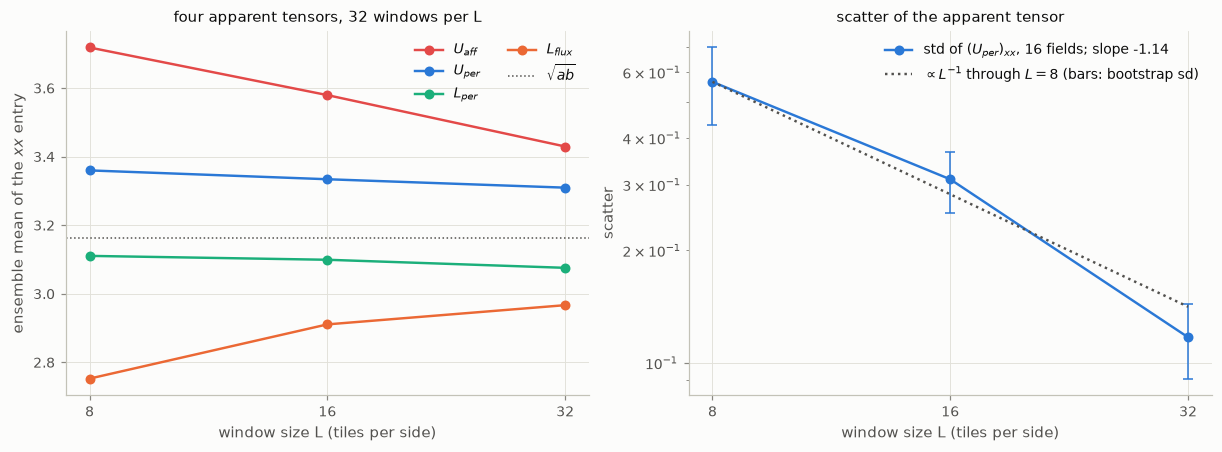

In [16]:
# figure 5: windows
fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
for key, lab, col in (("Ua", r"$U_{aff}$", CAT[7]), ("Up", r"$U_{per}$", CAT[0]), ("Lp", r"$L_{per}$", CAT[2]), ("Lf", r"$L_{flux}$", CAT[1])):
    mu = [np.mean([rec[t][key][0, 0] for rec in WIN[Lt] for t in ("s", "sw")]) for Lt in sorted(WIN)]
    ax[0].semilogx(Ls, mu, "o-", color=col, label=lab)
ax[0].axhline(np.sqrt(A_ * B_), color=INK2, ls=":", lw=1.0, label=r"$\sqrt{ab}$")
ax[0].set_xlabel("window size L (tiles per side)"); ax[0].set_ylabel(r"ensemble mean of the $xx$ entry"); ax[0].set_title("four apparent tensors, 32 windows per L")
ax[0].set_xticks(Ls); ax[0].set_xticklabels([str(int(l)) for l in Ls]); ax[0].minorticks_off(); ax[0].legend(ncol=2)
ax[1].errorbar(Ls, [STD[int(l)][0] for l in Ls], yerr=[STD[int(Ls[i])][0] * (np.exp(sd_logstd[i]) - 1) for i in range(3)], fmt="none", ecolor=CAT[0], capsize=3, lw=1.0)
ax[1].loglog(Ls, [STD[int(l)][0] for l in Ls], "o-", color=CAT[0], label=rf"std of $(U_{{per}})_{{xx}}$, 16 fields; slope {slope:+.2f}")
ax[1].loglog(Ls, STD[8][0] * (Ls / 8.0) ** -1.0, ":", color=INK2, label=r"$\propto L^{-1}$ through $L=8$ (bars: bootstrap sd)")
ax[1].set_xlabel("window size L (tiles per side)"); ax[1].set_ylabel("scatter"); ax[1].set_title("scatter of the apparent tensor"); ax[1].legend()
ax[1].set_xticks(Ls); ax[1].set_xticklabels([str(int(l)) for l in Ls]); ax[1].xaxis.set_minor_locator(plt.NullLocator())
plt.show()

*Figure 5.* Left: ensemble means of the $xx$ entries of the four tensors against the window size (32 windows per size); the dotted line is $\sqrt{ab}$. Right: the scatter of $(U_{\rm per})_{xx}$ against $L$, with $L^{-1}$ dotted.

Reading the printed outcomes.

- The ordering holds in all $96$ windows with large margins (the smallest eigenvalue of any of the three differences is $0.045$ or more), so there is no near-violation to explain.
- The ensemble means show the hierarchy: the affine mean falls and the flux mean rises with $L$ while the periodic ones are nearly flat, and $\sqrt{ab}$ lies between the means of $L_{\rm per}$ and $U_{\rm per}$ at every $L$.
- The bracket of ensemble geometric means is centered on $\sqrt{ab}$ to rounding at every $L$, as the unit test says. Its relative half-width, the printed ratio $1.037$ to $1.039$ of the geometric mean of $U_{\rm per}$ to $\sqrt{ab}$ at $m=4$, does *not* shrink with $L$: at $m=4$ pixels per tile the interval is limited by the pixel discretization, not by the window size (see the next item for the dependence on $m$).
- Scatter: the fitted slope is $-1.14$ with bootstrap standard deviation $0.21$, so the central-limit slope $-1$ is not inconsistent with the data. The power to discriminate is low: with 16 fields per size and three sizes, the window of $\pm3$ bootstrap standard deviations is $[-1.64,-0.36]$, which also contains $-1.6$ and $-0.5$. The check passes, but it could not have distinguished those alternatives.
- The half-width of the bracket of ensemble geometric means depends on the pixels per tile: at $L=8$ it is $1.075$, $1.039$, $1.022$ for $m=2,4,8$, and at $L=16$ it is $1.071$, $1.037$, $1.020$. So at fixed $m$ it is pixel-limited (it does not change with $L$ at $m=4$) and it decreases with $m$ over the three values tried; whether it tends to zero as $m\to\infty$ is not tested (only $m\le8$ and $L\le16$ here, with 32 windows each).

In [17]:
print(f"total run time of the notebook: {time.perf_counter() - T0:.1f} s   (sections: " + ", ".join(f"{k}: {v:.1f} s" for k, v in SEC.items()) + ")")

total run time of the notebook: 93.9 s   (sections: 1: 0.2 s, 2 (incl. the Q1 table to N = 512): 41.7 s, 3: 17.6 s, 4a: 0.0 s, 4b: 7.7 s, 4c: 10.7 s, 5: 10.8 s)


## Caveats and open ends

- **What is certified and what is not.** The Q1 pair, the Fourier-Galerkin pair and the window orderings are rigorous statements (up to floating-point rounding, about $10^{-12}$ here) about the medium actually solved: a pixel medium in sections 1 to 3 and 5, the true disk in section 4. The Rayleigh multipole values are exact references converged to rounding, not certified. The sampled (Moulinec-Suquet) scheme is uncertified; its positive sign here is an observation.
- **The $\kappa=100$ rate is unresolved.** On the Q1 data alone the power-law extrapolation ($0.272$) lies above $2\lambda_1=0.2538$ and outside its own spread. The expectation $r_\infty=2\lambda_1$ rests on the corner theory and the heuristic scale $N^*=e^{1/\lambda_1}\approx2.6\times10^3$, beyond what was computed ($N=512$; the Q1 table up to $N=512$ for the three contrasts is the largest cost of the notebook, about $48$ s in section 2). The logarithmic extrapolation ($0.226$) is a device with no theoretical basis. The power-law fit uses $3$ parameters on $5$ points. At $\kappa=10$ the fit spread excludes $2\lambda_1$ by $3\times10^{-4}$.
- **The sampled-scheme rates are unexplained.** At $\kappa=10$ the local rate sits near $1.28$ (equal to $2\lambda_1+\tfrac12$ within $0.01$ at $N=2048$) but drifts by $0.02$ over the range; at $\kappa=100$ it is still falling. No law is claimed, and the numbers do not distinguish a slow drift to a limit from a preasymptotic effect.
- **Pre-asymptotic claims.** $N^*=e^{1/\lambda_1}$ is a heuristic scale. The energy-norm exponent $\lambda_1$ for conforming Q1 on these meshes is quoted from the general corner theory, not proven here; the notebook verifies it for $\kappa=4$ and $10$ only.
- **Staircase disks.** Only center-sampled disks at one center, $f=0.5$ and $0.7$, were tested, and the $f=0.5$ pair is one geometry by interchange. The shape part is certified only as an interval; the decay at $f=0.5$ is consistent with $O(h)$ but no rate is certified, and at $f=0.7$ the certified shape part is not monotone in $N$. The finer-mesh solves cover two staircases ($N_0=64,128$) at two geometries. A second disk center, $N=512$, and $f_{\rm pix}(N)$ for more $N$ were not tried, so the lattice-point reading of the area part is a hypothesis. Nothing here says how to correct a pixel disk; matching area and perimeter was not tried.
- **Windows.** Sixteen independent fields per size give a noisy scatter slope with low power against alternative laws; the $m=4$ pixels per tile limit the bracket, not the window, and the dependence on $m$ was tried for $m=2,4,8$ and $L=8,16$ only. The antithetic and ensemble-center checks are unit tests of the code path. Huet's theorem covers only the kinematic and static ends; the periodic middle is shown here by trial-space inclusion in two dimensions only.
- **Tolerances set after seeing results** (the rest are a priori): the Q1 local-rate tolerance $0.01$; the fitted-$r_\infty$ tolerance $2\times10^{-3}$ for $\kappa=4,10$ and the window $[0.005,0.04]$ for $\kappa=100$; the leave-one-out bound $10^{-3}$ and the margin $0.03$ at $\kappa=100$; the sampled-scheme rate bands (in $[1.26,1.30]$ at $\kappa=10$; within $0.02$ of $2\lambda_1+\tfrac12$ at $\kappa=10$; below $-0.2$ of it at $\kappa=100$; between $2\lambda_1$ and $4\lambda_1$ at $\kappa=100$; decreasing at $\kappa=100$); the factor-$0.1$ comparison with Q1 and the iteration ratio $2$; the ratio window $[0.9,1.2]$ for $(U-\sigma^*)/(\kappa(\sigma^*-L))$; the extrapolation tolerance $5\times10^{-4}$ (now for all three cases) and the midpoint lower bound $10^{-3}$; the staircase decay windows $[2,3]$ (lower end) and $[1.8,2.8]$ (upper end) per doubling; the half-width windows $[-0.01,0]$ at $m=4$ across $L$; the $3\sigma$ window for the scatter slope is a convention but its width is what makes the test weak. Checks that assert an observed fact rather than a theorem: the exception at weak $f=0.7$, $N=128$; the non-monotone $f=0.7$ shape part and its overlap check; the area-part sign changes; the monotone decrease of the half-width with $m$; the power-law fit being better than the logarithmic one. The tolerance $10^{-6}$ for the series constant is the truncation bound of a six-digit constant, a priori. The corner-singular-value tolerances ($10^{-14}$ at the closed form, $10^{-10}$ at the refined root) were set from the observed rounding level, not from a theorem.
- **Departures from the design in `PLAN.md`.** `PLAN.md` records the design, the expectations written before the computations, and the corrections made after an independent review. Corner roots are refined by golden-section search instead of Brent's bounded method (the latter limits accuracy to $\sim10^{-9}$ and made the $10^{-9}$ tolerance fail); the scatter slope is tested against $-1$ with a bootstrap standard deviation instead of a fixed window; the scatter uses the 16 independent fields instead of all 32 windows; the Q1 compensated-error percentages are quoted for the octave stated in the text; sections 2, 4 and 5 add the quarter-square identity, the one-sided-distance table, the area/shape decomposition with finer-mesh solves, the Keller-twin test and the $m$-dependence of the half-width. Checks that cannot fail are unit tests of interfaces or identities and are labeled as such (the interchange identities, the antithetic identity, the algebraic primal-primal relation).

## References

Checked against publisher or library records on 2026-11-23 (see `PLAN.md`):

- J. B. Keller, A theorem on the conductivity of a composite medium, J. Math. Phys. 5 (1964), 548-549.
- A. M. Dykhne, Conductivity of a two-dimensional two-phase system, Sov. Phys. JETP 32 (1971), 63-65 (Zh. Eksp. Teor. Fiz. 59 (1970), 110-115).
- K. S. Mendelson, A theorem on the effective conductivity of a two-dimensional heterogeneous medium, J. Appl. Phys. 46 (1975), 4740-4741.
- Lord Rayleigh, On the influence of obstacles arranged in rectangular order upon the properties of a medium, Phil. Mag. (5) 34 (1892), 481-502.
- W. T. Perrins, D. R. McKenzie, R. C. McPhedran, Transport properties of regular arrays of cylinders, Proc. R. Soc. Lond. A 369 (1979), 207-225.
- Z. Hashin, S. Shtrikman, A variational approach to the theory of the effective magnetic permeability of multiphase materials, J. Appl. Phys. 33 (1962), 3125-3131.
- R. B. Kellogg, Singularities in interface problems, in: Numerical Solution of Partial Differential Equations-II, Academic Press, 1971, 351-400; and On the Poisson equation with intersecting interfaces, Applicable Analysis 4 (1974/75), 101-129 (the four-quadrant exponents; the checkerboard formula is in the later paper).
- H. Moulinec, P. Suquet, A numerical method for computing the overall response of nonlinear composites with complex microstructure, Comput. Methods Appl. Mech. Engrg. 157 (1998), 69-94.
- J. Zeman, J. Vondrejc, J. Novak, I. Marek, Accelerating a FFT-based solver for numerical homogenization of periodic media by conjugate gradients, J. Comput. Phys. 229 (2010), 8065-8071.
- J. Vondrejc, J. Zeman, I. Marek, Guaranteed upper-lower bounds on homogenized properties by FFT-based Galerkin method, Comput. Methods Appl. Mech. Engrg. 297 (2015), 258-291.
- C. Huet, Application of variational concepts to size effects in elastic heterogeneous bodies, J. Mech. Phys. Solids 38 (1990), 813-841.
- G. W. Milton, The Theory of Composites, Cambridge University Press, 2002.
- R. V. Craster, Yu. V. Obnosov, Four-phase checkerboard composites, SIAM J. Appl. Math. 61 (2001), 1839, DOI 10.1137/S0036139900371825 (checked, bibliographic record only).
- G. W. Milton, Proof of a conjecture on the conductivity of checkerboards, J. Math. Phys. 42 (2001), 4873-4882 (checked, bibliographic record only).
- S. Mortola, S. Steffe, A two-dimensional homogenization problem, Atti Accad. Naz. Lincei Rend. Cl. Sci. Fis. Mat. Natur. (8) 78 (1985) (the conjecture) (from memory; the original record was not found).

Also cited from memory, not in the checked list: the Polya-Szego isoperimetric property of the polarizability invoked for the sign of the staircase shape part; T. Kanit et al., Int. J. Solids Struct. 40 (2003), 3647-3679 (periodic apparent properties between the kinematic and static ones); the energy-norm rate $O(h^{\lambda})$ for conforming elements at an interface corner (general finite-element corner theory, Babuska and Kellogg-type results).

In the repository: `notebooks/spatial_dispersion/` notebook 03 and `rodlattice.py` (the Rayleigh series check); `PLAN.md` of this folder.